# Same seed: temperature vs plan nudges (Qwen3-8B) — demo notebook

**Question.** When an LLM writes code for a task that has a well-known default solution, does turning up the
**temperature** make it choose a *different algorithm*, or only *phrase the same algorithm differently*? And does a
small **plan nudge** change the algorithm under the *same* token noise? A plan nudge is a random push added to the
residual stream at the task-specification tokens.

**Tasks** (each has a default the model almost always writes):
- **T2**: weighted shortest path; the default is Dijkstra.
- **T1**: grid path; the default is BFS.
- **T03**: k-th smallest; the default is a full sort.

**Design: a seed-coupled 2×2 on Qwen3-8B** (thinking off; FP8 W8A8 Hugging Face engine on a 16 GB RTX 2000 Ada).
Each task has 20 *token seeds* (prompt templates W1–W5 × k 0–3). Every seed keeps **one noise stream** across
*every* condition: PCG64 uniforms, with inverse-CDF sampling in vocabulary order. These are common random numbers
(CRN), so a seed's programs differ only by the condition.

| block | conditions sampled from every seed |
|---|---|
| NO-PN (temperature) | T 0.3 / 0.7 / 1.0 / 1.3 (top-p 1); top-k 10 at T 0.7; min-p 0.1 at T 2.0; a repeat of T 1.0 with other batch-mates (`FILLER`) |
| PN (plan noise) | 6 isotropic unit directions × α ∈ {1, 2} ban units × T ∈ {0.7, 1.0}. The push is added to the outputs of blocks 12–23 at the task-spec positions, prefill only |
| Gumbel-max replicate (`GB_*`, T2 and T03) | the same temperatures and PN (α 1, T 1.0) under an exponential-race coupling |

Every program is labelled at the mechanism level, e.g. `dijkstra`, `bf_spfa`, `quickselect`, `dfs`. The labeller
runs hidden tests and a runtime tracer first and AST rules second, and calls a blind LLM judge only when they
disagree.

**Key quantities**
- `C_T`: the number of seeds whose algorithm changes across the 4 temperatures.
- `C_PN`: the number of seeds whose algorithm changes across {no PN, 3 PN directions}. It is averaged over all
  C(6,3) = 20 direction subsets.
- `x_s`: a seed's PN change minus its temperature change. A one-sided sign-flip test checks mean `x_s` > 0, pooled
  over T2 and T03.
- **PPI** (*phrasings per idea*): the number of AST 4-gram clusters per algorithm. The slope of log PPI on T measures
  how fast temperature adds phrasings.

**Reported results of the full run:**
- **Temperature never changed the algorithm:** 0/20 seeds on every task.
- **Plan noise did** (α 1, T 1.0): **17.25/20** seeds on T2, **4.55** on T03 and 2.5 on T1.
- **The paired contrast is decisive:** pooled mean `x_s` = 0.545 [0.41, 0.67], sign-flip p = 1.0e-5.
- **Temperature adds phrasings, not ideas:** phrasings per idea grow with T (pooled slope 0.64–0.81).
- **Verdict: PARTIAL.** H-PN fails on T03, where 4.55 < 5.

**What this notebook runs.** `method.py` orchestrates 12 stages. The GPU sampling stages (Qwen3-8B: about 0.9 h on
HF and 1.7 h on vLLM) and the labelling stage cannot run in a short Colab session. Their output ships in
`mini_demo_data.json`: the **60 seeds** (T2, T03, T1 × 20) with all **2,380 labelled thinking-off programs**
sampled from them. On these programs the notebook runs the three CPU stages of `method.py`, with the original code:
1. **`tests`**: synthetic tests of the analysis code.
2. **`analyse`**: change counts, tests, phrasing, the verdict and figures.
3. **`rederive`**: an independent re-derivation of the headline numbers.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (the original code logs with loguru; version from env/requirements_hf.txt)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py
import argparse
import sys
from pathlib import Path

from loguru import logger

# analysis/core.py, analysis/report.py, audit/rederive.py, tests/test_analysis.py, src/cfg.py
import ast
import hashlib
import itertools
import json
import math
import random
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Callable, Iterable, Sequence

import numpy as np

# analysis/figures.py (notebook: `matplotlib.use("Agg")` is left out so figures can be shown inline)
import matplotlib
import matplotlib.pyplot as plt

# notebook only
import time
import types
import pandas as pd
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-4/experiment-21/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

# One example = one token seed (slot task|template|k); `programs` = every thinking-off program sampled from that
# seed's single noise stream, one per condition (`arm`).
meta = data["metadata"]
print(f"{meta['n_examples']} seeds, {meta['n_programs']} labelled programs")
print("label counts per task:", meta["label_counts"])
ex = data["examples"][0]
print(f"\nseed {ex['slot']} -- prompt:\n{ex['input']}\n")
print("algorithm label per condition for this seed:")
for p in ex["programs"]:
    print(f"  {p['arm']:<24} {p['label']:<10} {'pass' if p['passed'] else 'FAIL'}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
60 seeds, 2380 labelled programs
label counts per task: {'T2': {'dijkstra': 560, 'bf_spfa': 303, 'other': 17}, 'T03': {'full_sort': 788, 'quickselect': 84, 'size_k_heap': 8}, 'T1': {'bfs': 572, 'dfs': 48}}

seed T2|W1|0 -- prompt:
[T2 twin prompt W1, token seed slot k=0]
Do not use man and the house for this task.

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most 600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s.

Use only the Python standard library. Return only one ```python code block containi

## Configuration

The data are fixed: all 60 seeds and all of their programs. The tunable parameters are the Monte-Carlo sizes of the
CPU stages (permutation, bootstrap, placebo and rarefaction draws). Each line shows the **original value** in its
comment. Smaller values run faster but make the p-values coarser, because a sign-flip p cannot go below
1/(1 + draws). They can also make the calibration test 1b fail by chance.

In [5]:
# Monte-Carlo sizes of the CPU stages (all original values fit the 10-minute budget)
N_DRAWS_POOLED = 100_000          # original 100_000: sign-flip draws of the pooled H-CON test (also the Gumbel-max replicate)
N_DRAWS_TASK = 20_000             # original 20_000: sign-flip draws per task (descriptive)
PLACEBO_REPS = 200                # original 200: condition-permutation placebo datasets (A3)
PLACEBO_DRAWS = 5_000             # original 5_000: sign-flip draws inside each placebo dataset
GB_PLACEBO_REPS = 50              # original 50: placebo datasets for the Gumbel-max replicate (optional arm iii)
SEED_BOOT_REPS = 10_000           # original 10_000: seed-bootstrap resamples of mean x_s
PPI_BOOT_REPS = 2_000             # original 2_000: seed-bootstrap resamples of the log-PPI slope (single linkage)
PPI_BOOT_REPS_COMPLETE = 300      # original 300: same, complete linkage (robustness)
RAREFY_DRAWS = 1_000              # original 1_000: rarefaction draws (Hill-1 and PPI at depth 20)
TEST_1A_REPS = 400                # original 400: planted-effect datasets in CPU test 1a
TEST_1B_DATASETS = 200            # original 200: exchangeable-label datasets in CPU test 1b (calibration)
TEST_1B_DRAWS = 20_000            # original 20_000: sign-flip draws per calibration dataset in test 1b
REDERIVE_DRAWS = 20_000           # original 20_000: sign-flip draws of the independent re-derivation
REDERIVE_PLACEBO_REPS = 200       # original 200: placebo datasets of the re-derivation
REDERIVE_PLACEBO_DRAWS = 1_000    # original 1_000: sign-flip draws inside each re-derivation placebo

## The orchestrator: `method.py`

`method.py` is a thin dispatcher: `uv run method.py --stage <stage>` imports the stage's module and runs it. The
stages, in run order:

| stage | what it does | in this notebook |
|---|---|---|
| `setup` | S0: inputs, hashes, hardware, labeller re-check | not run (needs the run volume) |
| `screen` | S1 screen file + S2 power expectation | not run (its headline check is used by test 4) |
| **`tests`** | CPU synthetic tests of the analysis code | **runs** |
| `commit` | S3 commit #0: the pre-registration hash chain | not run (the chain is verified in `rederive`) |
| `src/vllm_think.py all` | G1: thinking-on T2 in vLLM, FP8 cross-check (GPU) | not run (its summary ships in the data) |
| `smoke`, `engine_check`, `grid`, `optional` (`hf_chain`) | HF GPU unit tests, positive control, **the 2×2**, optional arms | not run (**their programs are the data**) |
| `label` | hidden tests + runtime tracer + AST rules + blind judge | not run (labels ship in the data) |
| **`analyse`** | S9 analyses + figures | **runs** |
| `export` | `method_out.json` (+ mini / preview) | not run |
| **`rederive`** | independent re-derivation from the programs alone | **runs** |

Each stage's module code is copied into the cells below. Each stage then runs the way `main()` dispatches it:
`setup_logging(stage)` followed by the stage's entry function.

### How the programs were sampled (GPU stages, shown for reference)

The coupling that makes "same seed" meaningful has two parts:
- **One noise stream per seed.** Each seed (task, template, k) owns a fixed stream of uniforms.
- **The same uniform drives every condition.** At decoding step `i`, the stream's `u[i]` picks the token by inverse
  CDF. A condition only changes the probabilities the uniform is read against.

```python
def u_stream(*key, n=MAX_NEW_TOKENS):          # src/engine.py: one noise stream per seed (task, template, k)
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)

def _inverse_cdf(probs, u):                     # src/engine.py: token = first index whose CDF >= u[step]
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)
```

A temperature condition only rescales the logits (`scaled = logits / T` in `src/engine4.py:mask_probs`); the
uniforms stay the same. A PN condition edits the prefill residual stream instead: at the outputs of blocks 12–23, over
the task-spec positions, `h ← h + (α·n[l,p] − (h − h_twin)·u) u` for a fixed random unit direction `u`. The
uniforms again stay the same.

In [6]:
# ---- src/cfg.py (excerpt): paths and JSON helpers ----
ROOT = Path.cwd()   # notebook: outputs (results/, figures/, logs/) go next to the notebook (original: the artifact folder)
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


# ---- src/cfg4.py (excerpt): iteration-4 constants and condition names ----
DEFAULT4 = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort"}
TEMPS = (0.3, 0.7, 1.0, 1.3)
TOPK_T, TOPK_K = 0.7, 10
PN_TEMPS = (0.7, 1.0)
PN_ALPHAS = (1.0, 2.0)
PN_SEEDS = (46001, 46002, 46003, 46004, 46005, 46006)   # D1-D6 (collision check in S0)
SEED_K = (0, 1, 2, 3)
MINP_T, MINP_P = 2.0, 0.1
TPN_T, TPN_ALPHA = 0.7, 2.0


def fmt_t(t: float) -> str:
    return f"{float(t):.1f}"


def cond_nopn(t: float) -> str:
    return f"NOPN_T{fmt_t(t)}"


def cond_pn(seed: int, alpha: float, t: float) -> str:
    return f"PN_D{seed}_a{float(alpha):.1f}_T{fmt_t(t)}"

In [7]:
# ---- method.py: logging set-up used by every stage ----
def setup_logging(stage: str) -> None:
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(ROOT / "logs" / f"{stage}.log"), rotation="30 MB", level="DEBUG")

## The committed analysis core (`analysis/core.py`)

This module was hash-committed in commit #0, before any decisive sample was drawn. Its cells are copied verbatim.
Its definitions, quoted from its docstring:

```text
C1-seed analysis core (hash-committed in commit #0 before any decisive sample).

Definitions (verbatim from predictions/prereg_c1seed.json):
- A SEED is a slot (task, template w, k); 20 per task (W1-W5 x k 0-3).
- Label modes: 'primary' = catalogue label or 'other' of VALID programs ('invalid' = no code / syntax error / crash
  before the first traced op, and 'unresolved' (incl. exp17's 'disputed') are excluded); 'correct_only' = primary and
  passed the hidden tests; 'invalid_as_label' = 'invalid' counts as one more label value.
- changed(labels) = 1 if the valid labels contain >= 2 distinct values, 0 if they are all equal, None if fewer than
  2 valid labels (seed not countable for that set).
- changed_T(s) over {NOPN T0.3, T0.7, T1.0, T1.3}; changed_PN(s; S, alpha, T) over {NOPN at T} + {PN(d, alpha, T): d in S}.
- C_T = sum over countable seeds of changed_T; C_PN = mean over all C(6,3) = 20 subsets S of sum_s changed_PN(s; S)
  (uncountable (seed, S) pairs contribute 0 and are reported).
- x_s = mean over countable subsets of changed_PN(s; S, alpha 1, T 1.0) - changed_T(s), for seeds where both are
  defined; one-sided sign-flip permutation p (100,000 draws) for mean x_s > 0, pooled over T2 and T03 seeds.
- Phrasing: identifier-normalised AST 4-gram shingles, Jaccard, connected components at theta (complete linkage as
  robustness) within each (condition, idea); PPI = clusters / ideas present; slope of log PPI on T per task by seed
  bootstrap; pooled slope = mean of the task slopes.
```

The first cell below holds the label handling (which programs count) and the `(task, seed, arm)` index.

In [8]:
EXCLUDED = {"invalid", "unresolved", "disputed", None, ""}
THETAS = (0.7, 0.8, 0.9)
SUBSET_SIZE = 3


# ------------------------------------------------------------------------------------------------ labels
def norm_label(lab: str | None) -> str | None:
    if lab in ("disputed", "unresolved", "unknown", "inconsistent"):
        return "unresolved"
    return lab


def label_value(row: dict[str, Any] | None, mode: str = "primary") -> str | None:
    """Label used for change counting under a sensitivity mode; None = excluded."""
    if row is None:
        return None
    lab = norm_label(row.get("label"))
    if mode == "primary":
        return None if lab in EXCLUDED else lab
    if mode == "correct_only":
        return lab if (lab not in EXCLUDED and bool(row.get("passed"))) else None
    if mode == "invalid_as_label":
        return None if lab in ("unresolved", None, "") else lab
    if mode == "first_approach":
        return row.get("first_approach")
    raise ValueError(mode)


def changed(labels: Iterable[str | None], min_valid: int = 2) -> int | None:
    v = [l for l in labels if l is not None]
    if len(v) < min_valid:
        return None
    return int(len(set(v)) >= 2)


# ------------------------------------------------------------------------------------------------ indexing
def index_rows(rows: Iterable[dict[str, Any]]) -> dict[tuple[str, str, str], dict[str, Any]]:
    """{(task, seed_id, arm): row}; seed_id = 'W1|0'. Later duplicates are ignored (first row wins)."""
    out: dict[tuple[str, str, str], dict[str, Any]] = {}
    for r in rows:
        key = (r["task"], f"{r['template']}|{int(r['sample_id'])}", r["arm"])
        out.setdefault(key, r)
    return out


def seeds_of(templates: Sequence[str] = ("W1", "W2", "W3", "W4", "W5"), ks: Sequence[int] = (0, 1, 2, 3)) -> list[str]:
    return [f"{w}|{k}" for w in templates for k in ks]

**Change counts.** `changed(labels)` is 1 if a seed's valid labels contain ≥ 2 distinct algorithms.
- `C_T` sums `changed` over the 4 temperature conditions.
- `C_PN` averages, over all 20 three-direction subsets `S`, the number of seeds whose label set
  {NO-PN at T} ∪ {PN(d, α, T) : d ∈ S} is not constant.
- `x_s` is the seed-level contrast: the subset-mean PN change minus the temperature change.

In [9]:
# ------------------------------------------------------------------------------------------------ change counts
def changed_over(idx: dict, task: str, seed: str, arms: Sequence[str], mode: str = "primary") -> int | None:
    return changed([label_value(idx.get((task, seed, a)), mode) for a in arms])


def count_changed(idx: dict, task: str, seeds: Sequence[str], arms: Sequence[str],
                  mode: str = "primary") -> dict[str, Any]:
    per = {s: changed_over(idx, task, s, arms, mode) for s in seeds}
    vals = [v for v in per.values() if v is not None]
    return {"C": int(sum(vals)), "n_countable": len(vals), "n_seeds": len(seeds), "per_seed": per}


def subsets(items: Sequence[Any], k: int = SUBSET_SIZE) -> list[tuple[Any, ...]]:
    return list(itertools.combinations(list(items), k))


def c_pn(idx: dict, task: str, seeds: Sequence[str], nopn_arm: str, pn_arms: Sequence[str],
         mode: str = "primary", k: int = SUBSET_SIZE) -> dict[str, Any]:
    """Subset-averaged changed-seed count over all C(len(pn_arms), k) subsets."""
    subs = subsets(pn_arms, k)
    sums, uncountable = [], 0
    per_seed_mean: dict[str, float | None] = {}
    per_seed_vals: dict[str, list[int]] = {s: [] for s in seeds}
    for S in subs:
        tot = 0
        for s in seeds:
            v = changed_over(idx, task, s, [nopn_arm, *S], mode)
            if v is None:
                uncountable += 1
                continue
            tot += v
            per_seed_vals[s].append(v)
        sums.append(tot)
    for s in seeds:
        per_seed_mean[s] = float(np.mean(per_seed_vals[s])) if per_seed_vals[s] else None
    arr = np.array(sums, dtype=float)
    return {"C_PN": float(arr.mean()) if len(arr) else float("nan"), "min": float(arr.min()) if len(arr) else None,
            "median": float(np.median(arr)) if len(arr) else None, "max": float(arr.max()) if len(arr) else None,
            "n_subsets": len(subs), "uncountable_seed_subsets": uncountable, "subset_sums": sums,
            "per_seed_mean": per_seed_mean}


def x_contrast(changed_t: dict[str, int | None], pn_mean: dict[str, float | None]) -> dict[str, float]:
    """x_s = subset-mean changed_PN(s) - changed_T(s) over seeds where both are defined."""
    return {s: float(pn_mean[s]) - float(changed_t[s]) for s in changed_t
            if changed_t.get(s) is not None and pn_mean.get(s) is not None}

**Statistics.**
- A one-sided **sign-flip permutation test** of mean `x_s` > 0: under the null, each seed's contrast is symmetric
  around 0.
- A **seed bootstrap** CI.
- **Clopper–Pearson** bounds for "0 of 20 seeds changed".

In [10]:
def sign_flip_p(x: Sequence[float], n_draws: int = 100_000, seed: int = 20261021) -> dict[str, Any]:
    """One-sided sign-flip permutation test of mean(x) > 0. p = (1 + #{perm mean >= obs}) / (1 + n_draws)."""
    xa = np.asarray(list(x), dtype=float)
    n = len(xa)
    if n == 0:
        return {"n": 0, "mean": float("nan"), "p": float("nan")}
    obs = float(xa.mean())
    if np.allclose(xa, 0):
        return {"n": n, "mean": obs, "p": 1.0, "n_draws": 0, "note": "all x_s = 0"}
    rng = np.random.default_rng(seed)
    ge = 0
    chunk = 10_000
    done = 0
    while done < n_draws:
        m = min(chunk, n_draws - done)
        signs = rng.integers(0, 2, size=(m, n), dtype=np.int8) * 2 - 1
        means = (signs * xa[None, :]).mean(axis=1)
        ge += int((means >= obs - 1e-12).sum())
        done += m
    return {"n": n, "mean": obs, "p": (1 + ge) / (1 + n_draws), "n_draws": n_draws, "n_nonzero": int((xa != 0).sum())}


def seed_bootstrap_ci(x: Sequence[float], reps: int = 10_000, seed: int = 7, level: float = 0.95) -> tuple[float, float]:
    xa = np.asarray(list(x), dtype=float)
    if len(xa) == 0:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(xa), size=(reps, len(xa)))
    m = xa[idx].mean(axis=1)
    a = (1 - level) / 2
    return (float(np.quantile(m, a)), float(np.quantile(m, 1 - a)))


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    from scipy.stats import beta

    if n == 0:
        return (float("nan"), float("nan"))
    a = (1 - level) / 2
    lo = 0.0 if k == 0 else float(beta.ppf(a, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - a, k + 1, n - k))
    return (lo, hi)

**Phrasings.** A program's AST is linearised: identifiers are renamed in order of first appearance, constants are
reduced to their type, and docstrings and comments are dropped. It is then cut into 4-gram shingles. Two programs
with Jaccard ≥ θ are the same *phrasing*.
- PPI = (number of phrasing clusters within each algorithm) / (number of algorithms present).
- The slope of log PPI on T is bootstrapped over **seeds**, so a seed's coupled programs move together.

In [11]:
# ------------------------------------------------------------------------------------------------ shingles
class _Norm(ast.NodeVisitor):
    """Pre-order linearisation: node type names, operator classes, renamed identifiers (first appearance), constants
    as their type only. Docstrings are dropped (comments never reach the AST)."""

    def __init__(self) -> None:
        self.toks: list[str] = []
        self.names: dict[str, str] = {}

    def _id(self, name: str) -> str:
        if name not in self.names:
            self.names[name] = f"v{len(self.names)}"
        return self.names[name]

    def generic_visit(self, node: ast.AST) -> None:
        self.toks.append(type(node).__name__)
        for field, value in ast.iter_fields(node):
            if isinstance(value, list):
                body = value
                if field == "body" and body and isinstance(body[0], ast.Expr) and isinstance(
                        getattr(body[0], "value", None), ast.Constant) and isinstance(body[0].value.value, str):
                    body = body[1:]           # drop docstring
                for item in body:
                    if isinstance(item, ast.AST):
                        self.visit(item)
            elif isinstance(value, ast.AST):
                self.visit(value)
            elif field in ("id", "arg", "name", "asname") and isinstance(value, str):
                self.toks.append(self._id(value))
            elif field == "attr" and isinstance(value, str):
                self.toks.append("." + value)
            elif field == "module" and isinstance(value, str):
                self.toks.append("mod:" + value)

    def visit_Constant(self, node: ast.Constant) -> None:
        self.toks.append("Const:" + type(node.value).__name__)


def ast_tokens(code: str) -> list[str] | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, MemoryError, RecursionError):
        return None
    v = _Norm()
    try:
        v.visit(tree)
    except RecursionError:
        return None
    return v.toks


def shingles(code: str | None, n: int = 4) -> frozenset | None:
    if not code:
        return None
    toks = ast_tokens(code)
    if toks is None:
        return None
    if len(toks) < n:
        return frozenset([tuple(toks)])
    return frozenset(tuple(toks[i:i + n]) for i in range(len(toks) - n + 1))


def jaccard(a: frozenset | None, b: frozenset | None) -> float:
    if a is None or b is None:
        return float("nan")
    if not a and not b:
        return 1.0
    return len(a & b) / max(len(a | b), 1)


def jaccard_matrix(sh: Sequence[frozenset]) -> np.ndarray:
    n = len(sh)
    m = np.eye(n)
    for i in range(n):
        for j in range(i + 1, n):
            m[i, j] = m[j, i] = jaccard(sh[i], sh[j])
    return m


def n_components(J: np.ndarray, theta: float) -> int:
    """Connected components of the graph with an edge where Jaccard >= theta (single linkage)."""
    n = J.shape[0]
    if n == 0:
        return 0
    parent = list(range(n))

    def find(a: int) -> int:
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i in range(n):
        for j in range(i + 1, n):
            if J[i, j] >= theta - 1e-12:
                ri, rj = find(i), find(j)
                if ri != rj:
                    parent[ri] = rj
    return len({find(i) for i in range(n)})


def n_complete(J: np.ndarray, theta: float) -> int:
    """Complete-linkage clusters cut at distance 1 - theta (robustness)."""
    from scipy.cluster.hierarchy import fcluster, linkage
    from scipy.spatial.distance import squareform

    n = J.shape[0]
    if n <= 1:
        return n
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = linkage(squareform(D, checks=False), method="complete")
    return int(len(set(fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance"))))


def ppi(labels: Sequence[str], J: np.ndarray, theta: float, linkage_kind: str = "single") -> dict[str, Any]:
    """Phrasings per idea of one cell: programs grouped by idea label; clusters within each idea; PPI = clusters /
    ideas present. labels[i] is the idea of program i (J indexes the same programs)."""
    ideas = sorted(set(labels))
    if not ideas:
        return {"ppi": float("nan"), "clusters": 0, "ideas": 0, "by_idea": {}}
    by = {}
    tot = 0
    for idea in ideas:
        ii = [i for i, l in enumerate(labels) if l == idea]
        sub = J[np.ix_(ii, ii)]
        c = n_components(sub, theta) if linkage_kind == "single" else n_complete(sub, theta)
        by[idea] = {"n": len(ii), "clusters": c}
        tot += c
    return {"ppi": tot / len(ideas), "clusters": tot, "ideas": len(ideas), "by_idea": by}


def ols_slope(x: Sequence[float], y: Sequence[float]) -> float:
    xa, ya = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(ya)
    xa, ya = xa[ok], ya[ok]
    if len(xa) < 2 or np.ptp(xa) == 0:
        return float("nan")
    xm = xa - xa.mean()
    return float((xm * (ya - ya.mean())).sum() / (xm ** 2).sum())


def ppi_slope_bootstrap(cells: dict[float, dict[str, Any]], theta: float, reps: int = 2000, seed: int = 11,
                        linkage_kind: str = "single") -> dict[str, Any]:
    """cells[T] = {'seeds': [seed ids], 'labels': [idea per seed program], 'sh': [shingles]} for the NO-PN cells of one
    task (programs aligned by seed; a seed with no valid program at T is absent from that cell). The bootstrap
    resamples SEEDS (each seed's coupled programs move together)."""
    Ts = sorted(cells)
    allseeds = sorted({s for T in Ts for s in cells[T]["seeds"]})
    pos = {T: {s: i for i, s in enumerate(cells[T]["seeds"])} for T in Ts}
    Js = {T: jaccard_matrix(cells[T]["sh"]) for T in Ts}

    def stat(seed_list: list[str]) -> tuple[float, dict[float, float]]:
        vals = {}
        for T in Ts:
            ii = [pos[T][s] for s in seed_list if s in pos[T]]
            if not ii:
                vals[T] = float("nan")
                continue
            labs = [cells[T]["labels"][i] for i in ii]
            J = Js[T][np.ix_(ii, ii)]
            vals[T] = ppi(labs, J, theta, linkage_kind)["ppi"]
        return ols_slope(Ts, [math.log(v) if v and v > 0 else float("nan") for v in vals.values()]), vals
    obs, obs_vals = stat(allseeds)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(reps):
        samp = [allseeds[i] for i in rng.integers(0, len(allseeds), size=len(allseeds))]
        boots.append(stat(samp)[0])
    b = np.array([v for v in boots if np.isfinite(v)])
    return {"slope": obs, "ppi_by_T": {str(k): v for k, v in obs_vals.items()}, "boot": b,
            "ci95": (float(np.quantile(b, 0.025)), float(np.quantile(b, 0.975))) if len(b) else (float("nan"),) * 2}

**Diversity and the pre-registered verdict.** Hill-1 is the exponential of the Shannon entropy of the correct ideas;
it is rarefied to one program per seed for the PN cells. `decide()` applies the committed outcome rules:
- **H-T**: every `C_T` ≤ 1.
- **H-PN**: `C_PN(α 1, T 1.0)` ≥ 5 on both T2 and T03.
- **H-PHR**: every pooled PPI slope > 0, with its CI excluding 0.
- **H-CON**: sign-flip p < 0.05.

In [12]:
# ------------------------------------------------------------------------------------------------ diversity
def hill1(labels: Sequence[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    p = np.array(list(c.values()), float) / n
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(per_seed_options: dict[str, list[str | None]], draws: int = 1000, seed: int = 5) -> dict[str, Any]:
    """per_seed_options[s] = labels (None = not counted, e.g. not correct) of the seed's programs in a PN cell (one per
    direction). Each draw takes one program per seed (depth = number of seeds) and computes Hill-1 over the counted
    labels."""
    rng = np.random.default_rng(seed)
    seeds = sorted(per_seed_options)
    vals, depths = [], []
    for _ in range(draws):
        labs = []
        for s in seeds:
            opts = per_seed_options[s]
            if not opts:
                continue
            l = opts[int(rng.integers(0, len(opts)))]
            if l is not None:
                labs.append(l)
        if labs:
            vals.append(hill1(labs))
            depths.append(len(labs))
    return {"hill1_mean": float(np.mean(vals)) if vals else float("nan"),
            "hill1_q05": float(np.quantile(vals, 0.05)) if vals else float("nan"),
            "hill1_q95": float(np.quantile(vals, 0.95)) if vals else float("nan"),
            "mean_counted_depth": float(np.mean(depths)) if depths else 0.0}


def js_bits(c1: Counter | dict, c2: Counter | dict) -> float:
    keys = sorted(set(c1) | set(c2))
    p = np.array([c1.get(k, 0) for k in keys], float)
    q = np.array([c2.get(k, 0) for k in keys], float)
    if p.sum() == 0 or q.sum() == 0:
        return float("nan")
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        ok = a > 0
        return float((a[ok] * np.log2(a[ok] / b[ok])).sum())
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def template_resampling_null(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], key: Callable[[dict], Any],
                             reps: int = 2000, seed: int = 3) -> dict[str, Any]:
    """JS between two compositions vs a null that pools both arms and resamples templates (with replacement, within the
    pooled arm) to form two pseudo-arms of the original template counts."""
    obs = js_bits(Counter(key(r) for r in rows_a if key(r) is not None),
                  Counter(key(r) for r in rows_b if key(r) is not None))
    pool = rows_a + rows_b
    by_t: dict[str, list[dict[str, Any]]] = {}
    for r in pool:
        by_t.setdefault(r["template"], []).append(r)
    temps = sorted(by_t)
    rng = np.random.default_rng(seed)
    null = []
    na = Counter(r["template"] for r in rows_a)
    nb = Counter(r["template"] for r in rows_b)
    for _ in range(reps):
        def pseudo(counts: Counter) -> Counter:
            c: Counter = Counter()
            for w, n in counts.items():
                src = by_t[temps[int(rng.integers(0, len(temps)))]]
                for i in rng.integers(0, len(src), size=n):
                    v = key(src[int(i)])
                    if v is not None:
                        c[v] += 1
            return c
        null.append(js_bits(pseudo(na), pseudo(nb)))
    nb_ = np.array([v for v in null if np.isfinite(v)])
    return {"js_bits": obs, "null_p95": float(np.quantile(nb_, 0.95)) if len(nb_) else float("nan"),
            "p": float((1 + (nb_ >= obs - 1e-12).sum()) / (1 + len(nb_))) if len(nb_) else float("nan")}


# ------------------------------------------------------------------------------------------------ verdict
def decide(res: dict[str, Any]) -> dict[str, Any]:
    """Apply the committed outcome rules. res keys: C_T[cell] (ints), C_PN_a1_T1[task] (floats), phr[theta] = {slope,
    ci95}, hcon = {mean, p}."""
    ht_cells = res["C_T"]
    h_t = all(v is not None and v <= 1 for v in ht_cells.values())
    h_pn = all(res["C_PN_a1_T1"].get(t, 0) >= 5 for t in ("T2", "T03"))
    h_phr = all(np.isfinite(v["slope"]) and v["slope"] > 0 and v["ci95"][0] > 0 for v in res["phr"].values())
    h_con = res["hcon"]["p"] < 0.05 and res["hcon"]["mean"] > 0
    disconf = (res["hcon"]["mean"] <= 0) or all(
        (res["C_T_off"].get(t, 0) >= res["C_PN_a1_T1"].get(t, 0)) for t in ("T2", "T03"))
    if h_t and h_pn and h_phr and h_con:
        verdict = "CONFIRMED"
    elif disconf:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    failed = [n for n, ok in (("H-T", h_t), ("H-PN", h_pn), ("H-PHR", h_phr), ("H-CON", h_con)) if not ok]
    note = ""
    if verdict == "PARTIAL" and h_t and all(1 <= res["C_PN_a1_T1"].get(t, 0) <= 4 for t in ("T2", "T03")):
        note = "temperature inert but PN weaker than predicted"
    return {"verdict": verdict, "H-T": h_t, "H-PN": h_pn, "H-PHR": h_phr, "H-CON": h_con, "failed_parts": failed,
            "note": note}

In [13]:
# notebook: the stage code below calls the committed core as `core.<name>` (it did `import core`); collect the
# core functions defined above under that name
core = types.SimpleNamespace(**{n: globals()[n] for n in (
    "EXCLUDED", "THETAS", "SUBSET_SIZE", "norm_label", "label_value", "changed",
    "index_rows", "seeds_of", "changed_over", "count_changed", "subsets", "c_pn",
    "x_contrast", "sign_flip_p", "seed_bootstrap_ci", "clopper_pearson", "ast_tokens", "shingles",
    "jaccard", "jaccard_matrix", "n_components", "n_complete", "ppi", "ols_slope",
    "ppi_slope_bootstrap", "hill1", "rarefied_hill1", "js_bits", "template_resampling_null", "decide")})
print(len(vars(core)), "core names:", ", ".join(vars(core)))

30 core names: EXCLUDED, THETAS, SUBSET_SIZE, norm_label, label_value, changed, index_rows, seeds_of, changed_over, count_changed, subsets, c_pn, x_contrast, sign_flip_p, seed_bootstrap_ci, clopper_pearson, ast_tokens, shingles, jaccard, jaccard_matrix, n_components, n_complete, ppi, ols_slope, ppi_slope_bootstrap, hill1, rarefied_hill1, js_bits, template_resampling_null, decide


## Stage `tests`: synthetic tests of the analysis code (`tests/test_analysis.py`)

These tests ran before commit #0, so the analysis was validated on data with a known answer:
- **1a, planted effect.** Temperature is inert and 3 of 6 PN directions escape with p = 0.4. `C_T` must be 0, and
  `C_PN` must match its analytic expectation within Monte-Carlo error.
- **1b, planted null.** PN rows copy the NO-PN row, so `x_s` = 0. Calibration: on 200 exchangeable-label datasets,
  the share of sign-flip p < 0.05 must lie in [0.02, 0.09].
- **1c.** How `invalid` and `unresolved` labels are treated under the three label modes.
- **2, shingles.** Identical or renamed programs give Jaccard 1, BFS vs DFS references give < 0.6, and cluster
  counts are monotone in θ.
- **4.** The screen file reproduces exp17's headline counts.

Changes from the original:
- Test 2 reads the T1 grid reference programs from `data` instead of `inputs/exp8/...`.
- Test 4 reads the screen headline check from `data` instead of `results/screen.json`.
- Loop sizes come from the config.

In [14]:
TEMP_ARMS = ["NOPN_T0.3", "NOPN_T0.7", "NOPN_T1.0", "NOPN_T1.3"]
DIRS = [46001, 46002, 46003, 46004, 46005, 46006]
PN_ARMS = [f"PN_D{d}_a1.0_T1.0" for d in DIRS]
SEEDS = core.seeds_of()

def _rows(task: str, labels: dict[tuple[str, str], str], passed: bool = True) -> list[dict]:
    out = []
    for (seed, arm), lab in labels.items():
        w, k = seed.split("|")
        out.append({"task": task, "template": w, "sample_id": int(k), "arm": arm, "label": lab, "passed": passed})
    return out


def planted_effect(rng: np.random.Generator, p: float = 0.4, escaping: tuple[int, ...] = (0, 1, 2)) -> list[dict]:
    lab = {}
    for s in SEEDS:
        for a in TEMP_ARMS:
            lab[(s, a)] = "dijkstra"
        for j, a in enumerate(PN_ARMS):
            lab[(s, a)] = "bf_spfa" if (j in escaping and rng.random() < p) else "dijkstra"
    return _rows("T2", lab)


def test_1a() -> dict:
    rng = np.random.default_rng(1)
    subs = core.subsets(PN_ARMS)
    analytic = 20 * np.mean([1 - 0.6 ** sum(1 for a in S if PN_ARMS.index(a) < 3) for S in subs])
    vals, cts = [], []
    for _ in range(TEST_1A_REPS):
        idx = core.index_rows(planted_effect(rng))
        cts.append(core.count_changed(idx, "T2", SEEDS, TEMP_ARMS)["C"])
        vals.append(core.c_pn(idx, "T2", SEEDS, "NOPN_T1.0", PN_ARMS)["C_PN"])
    vals = np.array(vals)
    se = vals.std(ddof=1) / np.sqrt(len(vals))
    ok = (max(cts) == 0 and len(subs) == 20 and abs(vals.mean() - analytic) < 4 * se)
    return {"pass": bool(ok), "C_T_max": int(max(cts)), "n_subsets": len(subs), "C_PN_mean": float(vals.mean()),
            "analytic": float(analytic), "mc_se": float(se)}


def test_1b() -> dict:
    # exact copy null: temperature inert, PN rows copy the same-T NOPN row
    lab = {}
    for s in SEEDS:
        for a in TEMP_ARMS:
            lab[(s, a)] = "dijkstra"
        for a in PN_ARMS:
            lab[(s, a)] = lab[(s, "NOPN_T1.0")]
    idx = core.index_rows(_rows("T2", lab))
    ct = core.count_changed(idx, "T2", SEEDS, TEMP_ARMS)["per_seed"]
    pm = core.c_pn(idx, "T2", SEEDS, "NOPN_T1.0", PN_ARMS)["per_seed_mean"]
    x = core.x_contrast(ct, pm)
    copy_ok = all(v == 0 for v in x.values()) and core.sign_flip_p(list(x.values()))["p"] == 1.0
    # calibration under exchangeable labels (every condition of a seed iid), 40 seeds, 200 datasets
    rng = np.random.default_rng(2)
    ps = []
    choices = np.array(["dijkstra", "bf_spfa", "other"])
    for rep in range(TEST_1B_DATASETS):
        xs = []
        for task in ("T2", "T03"):
            lab = {}
            for s in SEEDS:
                for a in TEMP_ARMS + PN_ARMS:
                    lab[(s, a)] = str(rng.choice(choices, p=[0.85, 0.10, 0.05]))
            idx = core.index_rows(_rows(task, lab))
            ct = core.count_changed(idx, task, SEEDS, TEMP_ARMS)["per_seed"]
            pm = core.c_pn(idx, task, SEEDS, "NOPN_T1.0", PN_ARMS)["per_seed_mean"]
            xs += list(core.x_contrast(ct, pm).values())
        ps.append(core.sign_flip_p(xs, n_draws=TEST_1B_DRAWS, seed=rep)["p"])
    share = float(np.mean(np.array(ps) < 0.05))
    return {"pass": bool(copy_ok and 0.02 <= share <= 0.09), "copy_null_all_x_zero": bool(copy_ok),
            "calibration_share_p_lt_0.05": share, "n_datasets": TEST_1B_DATASETS,
            "calibration_quantiles_p": [float(np.quantile(ps, q)) for q in (0.05, 0.25, 0.5, 0.75)]}


def test_1c() -> dict:
    lab = {("W1|0", "NOPN_T0.3"): "dijkstra", ("W1|0", "NOPN_T0.7"): "invalid", ("W1|0", "NOPN_T1.0"): "dijkstra",
           ("W1|0", "NOPN_T1.3"): "unresolved",
           ("W1|1", "NOPN_T0.3"): "invalid", ("W1|1", "NOPN_T0.7"): "invalid", ("W1|1", "NOPN_T1.0"): "dijkstra",
           ("W1|1", "NOPN_T1.3"): "disputed"}
    idx = core.index_rows(_rows("T2", lab))
    s = ["W1|0", "W1|1"]
    prim = core.count_changed(idx, "T2", s, TEMP_ARMS, "primary")["per_seed"]
    inv = core.count_changed(idx, "T2", s, TEMP_ARMS, "invalid_as_label")["per_seed"]
    rows_fail = _rows("T2", {("W1|2", a): ("bfs" if a == "NOPN_T1.3" else "dijkstra") for a in TEMP_ARMS}, passed=False)
    idx2 = core.index_rows(rows_fail)
    co = core.count_changed(idx2, "T2", ["W1|2"], TEMP_ARMS, "correct_only")["per_seed"]
    ok = (prim == {"W1|0": 0, "W1|1": None} and inv == {"W1|0": 1, "W1|1": 1} and co == {"W1|2": None})
    return {"pass": bool(ok), "primary": prim, "invalid_as_label": inv, "correct_only_all_failing": co}

In [15]:
def test_2() -> dict:
    a = "def solve(n, edges, s, t):\n    # comment\n    dist = [1000000000] * n\n    dist[s] = 0\n    return dist[t]\n"
    b = "def solve(m, e, src, dst):\n    '''doc'''\n    d = [7] * m  # other\n    d[src] = 1\n    return d[dst]\n"
    sa, sb = core.shingles(a), core.shingles(b)
    suite = data["metadata"]["t1_grid_references"]   # notebook: {file name: source} of inputs/exp8/suite/tasks/t1_grid/references
    bfs = core.shingles(suite["bfs_deque_parent.py"])
    dfs = core.shingles(suite["dfs_stack.py"])
    dfs_r = core.shingles(suite["dfs_recursive.py"])
    j_id = core.jaccard(sa, sa)
    j_ren = core.jaccard(sa, sb)
    j_bd = core.jaccard(bfs, dfs)
    j_bdr = core.jaccard(bfs, dfs_r)
    progs = [suite[p] for p in sorted(suite)]
    bfs_txt = suite["bfs_deque_parent.py"]
    progs += [bfs_txt.replace("queue", "q_renamed"), bfs_txt + "\n\ndef helper(x):\n    return x + 1\n",
              bfs_txt + "\n\ndef helper(x):\n    y = [x]\n    for i in range(3):\n        y.append(i)\n    return y\n"]
    J = core.jaccard_matrix([core.shingles(p) for p in progs])
    counts = [core.n_components(J, th) for th in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95)]
    mono = all(x <= y for x, y in zip(counts, counts[1:]))
    cl = [core.n_complete(J, th) for th in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95)]
    mono_c = all(x <= y for x, y in zip(cl, cl[1:]))
    ok = j_id == 1.0 and j_ren == 1.0 and j_bd < 0.6 and j_bdr < 0.6 and mono and mono_c
    return {"pass": bool(ok), "identical": j_id, "renamed_constants_comments": j_ren, "bfs_vs_dfs_stack": j_bd,
            "bfs_vs_dfs_recursive": j_bdr, "components_by_theta": counts, "complete_by_theta": cl}


def test_4() -> dict:
    s = {"headline_check": data["metadata"]["screen_headline_check"]}   # notebook: results/screen.json
    chk = s["headline_check"]
    return {"pass": bool(chk["ruleB_matches"]), "ruleB": chk["ruleB"], "ruleA": chk["ruleA"],
            "expected": chk["expected"], "note": "rule A (excess only) gives T2 5/15: reported as a mismatch of that "
            "reading; rule B (excess and pass ratio >= 0.85) reproduces both counts"}


def run_all_tests() -> dict:
    res = {"utc": utc_now()}
    for name, fn in (("1a_planted_effect", test_1a), ("1b_planted_null", test_1b), ("1c_label_modes", test_1c),
                     ("2_shingles", test_2), ("4_screen_headlines", test_4)):
        try:
            res[name] = fn()
        except Exception as e:  # noqa: BLE001 - a failing test is recorded, never hidden
            logger.exception(f"test {name} crashed")
            res[name] = {"pass": False, "error": repr(e)}
        logger.info(f"test {name}: {res[name]}")
    res["all_pass"] = all(v.get("pass") for k, v in res.items() if isinstance(v, dict))
    write_json(RESULTS_DIR / "tests_cpu.json", res)
    logger.info(f"CPU tests all_pass={res['all_pass']}")
    return res

In [16]:
# method.py --stage tests
t0 = time.time()
setup_logging("tests")
tests_res = run_all_tests()
print(f"\nstage tests: all_pass = {tests_res['all_pass']}  ({time.time() - t0:.1f} s)")

11:19:39|INFO   |test 1a_planted_effect: {'pass': True, 'C_T_max': 0, 'n_subsets': 20, 'C_PN_mean': 10.18925, 'analytic': 10.144000000000002, 'mc_se': 0.07136003243639473}


11:19:40|INFO   |test 1b_planted_null: {'pass': True, 'copy_null_all_x_zero': True, 'calibration_share_p_lt_0.05': 0.05, 'n_datasets': 200, 'calibration_quantiles_p': [0.05023998800059998, 0.23802559872006399, 0.49575021248937556, 0.7306259687015649]}


11:19:40|INFO   |test 1c_label_modes: {'pass': True, 'primary': {'W1|0': 0, 'W1|1': None}, 'invalid_as_label': {'W1|0': 1, 'W1|1': 1}, 'correct_only_all_failing': {'W1|2': None}}


11:19:40|INFO   |test 2_shingles: {'pass': True, 'identical': 1.0, 'renamed_constants_comments': 1.0, 'bfs_vs_dfs_stack': 0.11553030303030302, 'bfs_vs_dfs_recursive': 0.22821576763485477, 'components_by_theta': [12, 12, 12, 12, 12, 13], 'complete_by_theta': [12, 12, 12, 12, 13, 13]}


11:19:40|INFO   |test 4_screen_headlines: {'pass': True, 'ruleB': {'T03_alpha1': 7, 'T2_alpha1': 3}, 'ruleA': {'T03_alpha1': 7, 'T2_alpha1': 5}, 'expected': {'T03_alpha1': 7, 'T2_alpha1': 3}, 'note': 'rule A (excess only) gives T2 5/15: reported as a mismatch of that reading; rule B (excess and pass ratio >= 0.85) reproduces both counts'}


11:19:40|INFO   |CPU tests all_pass=True



stage tests: all_pass = True  (1.8 s)


## Stage `analyse`: S9 analyses (`analysis/report.py`)

`load_rows()` originally joins `data/samples_raw.jsonl` with `data/labels.jsonl`. Here it flattens the loaded seeds
into the same merged rows, one per program. Token ids ship as a sha1 fingerprint, because the analyses only test
whether two programs' token ids are equal.

In [17]:
TASKS = ("T2", "T03", "T1")
TEMP_ARMS = [cond_nopn(t) for t in TEMPS]
TOPK_ARM = f"TOPK{TOPK_K}_T{fmt_t(TOPK_T)}"
MINP_ARM = f"MINP_T{fmt_t(MINP_T)}"
THINK_ARMS = [f"THINK_T{fmt_t(t)}" for t in TEMPS]
SEEDS = core.seeds_of()
COUPLING = {"off": "inverse-CDF CRN (PCG64 uniforms, vocabulary order)",
            "on": "vLLM exponential race = Gumbel-max (per-request seed)",
            "gumbel": "HF exponential race = Gumbel-max (per-row CUDA generator)"}


def load_rows() -> list[dict[str, Any]]:
    # notebook: rows come from the loaded demo data (one example per seed, one program per arm) instead of joining
    # data/samples_raw.jsonl with data/labels.jsonl; token ids ship as a sha1 fingerprint (only equality is tested)
    out = []
    for ex in data["examples"]:
        for p in ex["programs"]:
            r = {"task": ex["task"], "template": ex["template"], "sample_id": ex["k"], **p}
            key = f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"
            out.append({**r, "key": key, "label": p["label"], "passed": bool(p["passed"]), "labelled": True,
                        "code": p.get("code"), "labeller_source": p.get("labeller_source"),
                        "token_ids": p["token_ids_sha1"]})
    return out


def rows_for(rows: list[dict[str, Any]], task: str, arm: str) -> list[dict[str, Any]]:
    return [r for r in rows if r["task"] == task and r["arm"] == arm]


def comp(rows: list[dict[str, Any]], correct: bool = False) -> dict[str, int]:
    c = Counter(core.label_value(r, "correct_only" if correct else "primary") for r in rows)
    c.pop(None, None)
    return dict(c.most_common())


def cp_rate(k: int, n: int) -> dict[str, Any]:
    lo, hi = core.clopper_pearson(k, n)
    return {"k": k, "n": n, "rate": k / n if n else None, "cp95": [lo, hi]}

### A1–A3: change counts, per-direction landings, and the paired seed contrast
- **A1, `a1_ct`.** `C_T` under three label modes: primary, correct-only, and invalid-as-label. Each comes with a
  Clopper–Pearson bound on the per-seed change rate.
- **A2, `a2_cpn`.** `C_PN` for each (α, T) cell. `per_direction` gives each direction's off-default share, pass rate
  and *landing* (which algorithm the nudged programs switch to).
- **A3, `a3_contrast`.**
  - per-seed `x_s` and the pooled sign-flip test (the artifact's Holm entry, C1-seed);
  - a condition-shuffle placebo, whose p should be ≈ uniform;
  - an assumption-light within-seed permutation test.

In [18]:
def a1_ct(idx: dict, task: str, arms: list[str], seeds: list[str] = SEEDS) -> dict[str, Any]:
    out = {}
    for mode in ("primary", "correct_only", "invalid_as_label"):
        c = core.count_changed(idx, task, seeds, arms, mode)
        out[mode] = {"C_T": c["C"], "n_countable": c["n_countable"], "cp95_rate": cp_rate(c["C"], c["n_countable"]),
                     "changed_seeds": sorted(s for s, v in c["per_seed"].items() if v)}
    return out


def pairwise_t(idx: dict, task: str, arms: list[str]) -> dict[str, Any]:
    out = {}
    for a, b in __import__("itertools").combinations(arms, 2):
        c = core.count_changed(idx, task, SEEDS, [a, b])
        out[f"{a}|{b}"] = {"changed": c["C"], "n": c["n_countable"]}
    return out


def a2_cpn(idx: dict, task: str, prefix: str = "") -> dict[str, Any]:
    out = {}
    for a in PN_ALPHAS:
        for t in PN_TEMPS:
            arms = [prefix + cond_pn(d, a, t) for d in PN_SEEDS]
            if not any((task, s, arms[0]) in idx for s in SEEDS):
                continue
            r = core.c_pn(idx, task, SEEDS, prefix + cond_nopn(t), arms)
            rc = core.c_pn(idx, task, SEEDS, prefix + cond_nopn(t), arms, mode="correct_only")
            out[f"a{a:.1f}_T{fmt_t(t)}"] = {"C_PN": r["C_PN"], "min": r["min"], "median": r["median"], "max": r["max"],
                                            "subset_sums": r["subset_sums"], "uncountable": r["uncountable_seed_subsets"],
                                            "C_PN_correct_only": rc["C_PN"], "per_seed_mean": r["per_seed_mean"]}
    return out


def per_direction(rows: list[dict[str, Any]], task: str, prefix: str = "") -> dict[str, Any]:
    out = {}
    de = DEFAULT4[task]
    for t in PN_TEMPS:
        base = rows_for(rows, task, prefix + cond_nopn(t))
        bv = [core.label_value(r) for r in base]
        bv = [x for x in bv if x]
        b_off = sum(x != de for x in bv) / max(len(bv), 1)
        b_pass = sum(r["passed"] for r in base) / max(len(base), 1)
        for a in PN_ALPHAS:
            for d in PN_SEEDS:
                rr = rows_for(rows, task, prefix + cond_pn(d, a, t))
                if not rr:
                    continue
                v = [core.label_value(r) for r in rr]
                v = [x for x in v if x]
                off = sum(x != de for x in v) / max(len(v), 1)
                pr = sum(r["passed"] for r in rr) / max(len(rr), 1)
                out[f"D{d}_a{a:.1f}_T{fmt_t(t)}"] = {
                    "N": len(rr), "n_valid": len(v), "share_off": off, "nopn_share_off": b_off,
                    "excess": off - b_off, "pass_rate": pr, "pass_ratio": pr / max(b_pass, 1e-9),
                    "escape_descriptive": (off - b_off >= 0.20 and pr / max(b_pass, 1e-9) >= 0.85),
                    "landing": dict(Counter(x for x in v if x != de).most_common()),
                    "mean_disp_S_b23": float(np.mean([r.get("disp_S_mean_b23") or 0 for r in rr])),
                    "mean_disp_S_b35": float(np.mean([r.get("disp_S_mean_b35") or 0 for r in rr])),
                    "mean_disp_R_b35": float(np.mean([r.get("disp_R_b35") or 0 for r in rr]))}
    return out

In [19]:
def a3_contrast(idx: dict, tasks: tuple[str, ...] = ("T2", "T03"), prefix: str = "", n_draws: int = 100_000,
                placebo_reps: int = 200) -> dict[str, Any]:
    xs_by_task = {}
    for task in TASKS:
        ct = core.count_changed(idx, task, SEEDS, [prefix + a for a in TEMP_ARMS])["per_seed"]
        pm = core.c_pn(idx, task, SEEDS, prefix + "NOPN_T1.0",
                       [prefix + cond_pn(d, 1.0, 1.0) for d in PN_SEEDS])["per_seed_mean"]
        xs_by_task[task] = core.x_contrast(ct, pm)
    out: dict[str, Any] = {"per_task": {}}
    for task, x in xs_by_task.items():
        v = list(x.values())
        out["per_task"][task] = {"n": len(v), "mean_x": float(np.mean(v)) if v else None,
                                 "boot95": core.seed_bootstrap_ci(v, reps=SEED_BOOT_REPS), "sign_flip": core.sign_flip_p(v, n_draws=N_DRAWS_TASK)}
    pooled = [v for t in tasks for v in xs_by_task[t].values()]
    out["pooled"] = {"tasks": list(tasks), "n": len(pooled), "mean_x": float(np.mean(pooled)) if pooled else float("nan"),
                     "boot95": core.seed_bootstrap_ci(pooled, reps=SEED_BOOT_REPS), "sign_flip": core.sign_flip_p(pooled, n_draws=n_draws)}
    # placebo: permute the 10 condition labels within each seed
    rng = np.random.default_rng(123)
    arms10 = [prefix + a for a in TEMP_ARMS] + [prefix + cond_pn(d, 1.0, 1.0) for d in PN_SEEDS]
    ps, pmeans = [], []
    for rep in range(placebo_reps):
        fake: dict = {}
        for task in tasks:
            for s in SEEDS:
                vals = [idx.get((task, s, a)) for a in arms10]
                perm = rng.permutation(len(vals))
                for a, j in zip(arms10, perm):
                    if vals[j] is not None:
                        fake[(task, s, a)] = vals[j]
        xx = []
        for task in tasks:
            ct = core.count_changed(fake, task, SEEDS, [prefix + a for a in TEMP_ARMS])["per_seed"]
            pm = core.c_pn(fake, task, SEEDS, prefix + "NOPN_T1.0", arms10[4:])["per_seed_mean"]
            xx += list(core.x_contrast(ct, pm).values())
        ps.append(core.sign_flip_p(xx, n_draws=PLACEBO_DRAWS, seed=rep)["p"])
        pmeans.append(float(np.mean(xx)) if xx else float("nan"))
    ps_a = np.array([p for p in ps if np.isfinite(p)])
    pm_a = np.array([m for m in pmeans if np.isfinite(m)])
    obs_m = out["pooled"]["mean_x"]
    out["within_seed_permutation_test"] = {
        "reps": len(pm_a), "observed_mean_x": obs_m, "placebo_mean_x_q95": float(np.quantile(pm_a, 0.95)) if len(pm_a) else None,
        "placebo_mean_x_max": float(pm_a.max()) if len(pm_a) else None,
        "p": float((1 + (pm_a >= obs_m - 1e-12).sum()) / (1 + len(pm_a))) if len(pm_a) else None,
        "note": "assumption-light robustness check of H-CON: condition labels permuted within seed (exchangeability "
                "null); not the committed test"}
    out["placebo_condition_permutation"] = {"reps": placebo_reps, "share_p_lt_0.05": float((ps_a < 0.05).mean()) if
                                            len(ps_a) else None, "median_p": float(np.median(ps_a)) if len(ps_a) else None,
                                            "note": "condition labels shuffled within seed; p should be ~uniform"}
    return out

### A4 / A5: phrasings
- **A4, `phrasing`.** For each task, the NO-PN programs at each temperature are grouped by algorithm and clustered
  by AST-shingle Jaccard at θ ∈ {0.7, 0.8, 0.9}. The slope of log PPI on T is bootstrapped over seeds, with
  complete linkage as a robustness check.
- **A5, `paired_phrasing`.** Compares two programs from the *same* seed under two conditions. When the algorithm is
  unchanged: how often are they byte-identical, and how similar are they? When it changed: how similar are they?

In [20]:
def phrasing(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    res: dict[str, Any] = {"thetas": list(core.THETAS), "per_task": {}, "pooled": {}}
    boots: dict[float, list[np.ndarray]] = defaultdict(list)
    slopes: dict[float, list[float]] = defaultdict(list)
    for task in TASKS:
        cells = {}
        for t, arm in zip(TEMPS, TEMP_ARMS):
            seeds, labs, sh = [], [], []
            for s in SEEDS:
                r = idx.get((task, s, arm))
                lab = core.label_value(r)
                shg = core.shingles(r.get("code")) if (r and lab) else None
                if lab and shg is not None:
                    seeds.append(s)
                    labs.append(lab)
                    sh.append(shg)
            cells[t] = {"seeds": seeds, "labels": labs, "sh": sh}
        tres = {}
        if sum(len(cells[t]["seeds"]) for t in TEMPS) == 0:
            for th in core.THETAS:
                tres[str(th)] = {"slope": float("nan"), "ci95": (float("nan"), float("nan")), "ppi_by_T": {}}
                boots[th].append(np.array([float("nan")]))
                slopes[th].append(float("nan"))
            res["per_task"][task] = {"theta": tres, "n_programs_by_T": {str(t): 0 for t in TEMPS}}
            continue
        for th in core.THETAS:
            b = core.ppi_slope_bootstrap(cells, th, reps=PPI_BOOT_REPS, seed=11)
            bc = core.ppi_slope_bootstrap(cells, th, reps=PPI_BOOT_REPS_COMPLETE, seed=12, linkage_kind="complete")
            tres[str(th)] = {"slope": b["slope"], "ci95": b["ci95"], "ppi_by_T": b["ppi_by_T"],
                             "complete_linkage": {"slope": bc["slope"], "ci95": bc["ci95"], "ppi_by_T": bc["ppi_by_T"]}}
            boots[th].append(b["boot"])
            slopes[th].append(b["slope"])
        res["per_task"][task] = {"theta": tres, "n_programs_by_T": {str(t): len(cells[t]["seeds"]) for t in TEMPS}}
    for th in core.THETAS:
        m = min(len(x) for x in boots[th])
        pooled_boot = np.mean([x[:m] for x in boots[th]], axis=0)
        res["pooled"][str(th)] = {"slope": float(np.mean(slopes[th])),
                                  "ci95": (float(np.quantile(pooled_boot, 0.025)), float(np.quantile(pooled_boot, 0.975)))}
    return res


def paired_phrasing(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    out: dict[str, Any] = {}
    shc: dict[str, Any] = {}

    def sh(r):
        if r is None or not r.get("code"):
            return None
        k = r["key"]
        if k not in shc:
            shc[k] = core.shingles(r["code"])
        return shc[k]
    for task in TASKS:
        tp: dict[str, Any] = {}
        pairs = [(a, b) for i, a in enumerate(TEMP_ARMS) for b in TEMP_ARMS[i + 1:]]
        for t in PN_TEMPS:
            for d in PN_SEEDS:
                pairs.append((cond_nopn(t), cond_pn(d, 1.0, t)))
        agg: dict[str, dict[str, list]] = defaultdict(lambda: {"same_ident": [], "same_j": [], "chg_ident": [],
                                                               "chg_j": []})
        for a, b in pairs:
            kind = "T_pair" if b.startswith("NOPN") else f"NOPN_vs_PN_a1_T{a[-3:]}"
            for s in SEEDS:
                ra, rb = idx.get((task, s, a)), idx.get((task, s, b))
                la, lb = core.label_value(ra), core.label_value(rb)
                if not (la and lb):
                    continue
                ident = ra.get("token_ids") == rb.get("token_ids")
                j = core.jaccard(sh(ra), sh(rb))
                key = "same" if la == lb else "chg"
                agg[kind][f"{key}_ident"].append(ident)
                if np.isfinite(j):
                    agg[kind][f"{key}_j"].append(j)
        for kind, v in agg.items():
            tp[kind] = {"n_same_idea": len(v["same_ident"]), "byte_identical_rate_same_idea":
                        float(np.mean(v["same_ident"])) if v["same_ident"] else None,
                        "mean_jaccard_same_idea": float(np.mean(v["same_j"])) if v["same_j"] else None,
                        "n_changed_idea": len(v["chg_ident"]),
                        "mean_jaccard_changed_idea": float(np.mean(v["chg_j"])) if v["chg_j"] else None}
        out[task] = tp
    return out

### A6: the per-condition table (the 1a–c question)

For every task × condition, the table gives:
- pass rate and composition (attempted and correct);
- Hill-1 of the correct ideas;
- phrasing clusters and PPI at each θ;
- paired Jaccard to the same seed's T 0.7 program.

PN cells pool the 6 directions. Hill-1 and PPI are rarefied there to one program per seed, so every cell has depth
20. The question it answers: does a tight temperature give 1 idea in 20 phrasings, or 20 ideas in one phrasing each?

In [21]:
def cell_hill(rows_cell: list[dict[str, Any]]) -> dict[str, Any]:
    labs = [core.label_value(r, "correct_only") for r in rows_cell]
    labs = [l for l in labs if l]
    return {"hill1_correct": core.hill1(labs) if labs else None, "n_correct": len(labs),
            "flag_fewer_than_20_correct": len(labs) < 20}


def table_1ac(rows: list[dict[str, Any]], idx: dict, cts: dict, cpns: dict) -> list[dict[str, Any]]:
    out = []
    for task in TASKS:
        base07 = {s: idx.get((task, s, "NOPN_T0.7")) for s in SEEDS}
        conds = TEMP_ARMS + [TOPK_ARM, MINP_ARM] + [f"PN_a{a:.1f}_T{fmt_t(t)}" for a in PN_ALPHAS for t in PN_TEMPS] + \
            ["GB_" + a for a in TEMP_ARMS] + ["GB_PN_a1.0_T1.0"]
        for c in conds:
            if c.startswith("PN_a") or c.startswith("GB_PN_a"):
                pre = "GB_" if c.startswith("GB_") else ""
                a = float(c.split("_a")[1].split("_")[0])
                t = float(c.split("_T")[1])
                arms = [pre + cond_pn(d, a, t) for d in PN_SEEDS]
                rr = [r for r in rows if r["task"] == task and r["arm"] in arms]
                if not rr:
                    continue
                opts = {s: [core.label_value(idx.get((task, s, arm)), "correct_only") for arm in arms
                            if idx.get((task, s, arm))] for s in SEEDS}
                rh = core.rarefied_hill1(opts, draws=RAREFY_DRAWS)
                hill = {"hill1_correct_rarefied20": rh["hill1_mean"], "hill1_q05": rh["hill1_q05"],
                        "hill1_q95": rh["hill1_q95"], "mean_counted_depth": rh["mean_counted_depth"]}
                key = f"a{a:.1f}_T{fmt_t(t)}"
                changed = (cpns.get(task, {}).get(key, {}) if not pre else cpns.get("GB_" + task, {}).get(key, {}))
                ch = changed.get("C_PN")
            else:
                rr = rows_for(rows, task, c)
                if not rr:
                    continue
                hill = cell_hill(rr)
                ch = None
            # phrasing clusters (single linkage) within (cell, idea)
            labs, shs, jp = [], [], []
            for r in rr:
                l = core.label_value(r)
                s = core.shingles(r.get("code")) if l else None
                if l and s is not None:
                    labs.append(l)
                    shs.append(s)
                b = base07.get(f"{r['template']}|{int(r['sample_id'])}")
                if b is not None and l and core.label_value(b) and b.get("code") and r.get("code"):
                    jp.append(core.jaccard(core.shingles(r["code"]), core.shingles(b["code"])))
            J = core.jaccard_matrix(shs) if shs else np.zeros((0, 0))
            cl = {str(th): core.ppi(labs, J, th) for th in core.THETAS}
            rare = None
            if (c.startswith("PN_a") or c.startswith("GB_PN_a")) and shs:
                # committed rarefaction: one program per seed (a random direction), 1,000 draws, depth <= 20
                seeds_of_prog = []
                for r in rr:
                    l = core.label_value(r)
                    if l and core.shingles(r.get("code")) is not None:
                        seeds_of_prog.append(f"{r['template']}|{int(r['sample_id'])}")
                by_seed: dict[str, list[int]] = defaultdict(list)
                for i, sd in enumerate(seeds_of_prog):
                    by_seed[sd].append(i)
                rng = np.random.default_rng(20)
                acc: dict[str, list[float]] = {str(th): [] for th in core.THETAS}
                for _ in range(RAREFY_DRAWS):
                    sel = [v[int(rng.integers(0, len(v)))] for v in by_seed.values()]
                    sl = [labs[i] for i in sel]
                    sj = J[np.ix_(sel, sel)]
                    for th in core.THETAS:
                        acc[str(th)].append(core.ppi(sl, sj, th)["ppi"])
                rare = {k: float(np.mean(v)) for k, v in acc.items()}
            out.append({"task": task, "condition": c, "N": len(rr),
                        "pass_rate": sum(r["passed"] for r in rr) / max(len(rr), 1),
                        "attempted": comp(rr), "correct": comp(rr, correct=True), **hill,
                        "clusters": {k: v["clusters"] for k, v in cl.items()},
                        "ppi": {k: v["ppi"] for k, v in cl.items()},
                        "ppi_rarefied20": rare,
                        "changed_seed_count": ch if ch is not None else (cts.get(task) if c in TEMP_ARMS else None),
                        "paired_jaccard_to_NOPN_T0.7": float(np.nanmean(jp)) if jp else None,
                        "coupling": COUPLING["gumbel"] if c.startswith("GB_") else COUPLING["off"]})
    return out

### CRN exactness check, optional arms, and the T × PN interaction
- **`determinism`.** The `FILLER_T1.0` repeat (same seed, different batch-mates) must be byte-identical to
  `NOPN_T1.0`. The engine-check rows (k 0–3) must also match it.
- **`optional_arms`.**
  - (iii) the Gumbel-max replicate (`GB_*`): `C_T`, `C_PN` and the contrast under a different coupling;
  - (iv) the min-p T 2.0 extended dial;
  - (ii) the thinking-on PN probe (`TPN_*` rows) ran in vLLM and is not in this subset, so it reports
    `available: False`.
- **`interaction`.** Under the escaping directions, does T 0.7 vs T 1.0 change the label more often than without
  PN?

Not copied here, because their inputs are not in the demo subset:
- `thinking()` needs `data/raw_thinking.jsonl`, the vLLM thinking-on traces of up to 16k tokens;
- `engine_check()` needs the screen's exp17 rows;
- `fp8_crosscheck()` needs the vLLM FP8 rows.

`run_analysis` takes their full-run results from `data["metadata"]["reported"]`.

In [22]:
def determinism(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    out = {}
    for task in TASKS:
        f_same, e_same = [], []
        for s in SEEDS:
            o = idx.get((task, s, "NOPN_T1.0"))
            f = idx.get((task, s, "FILLER_T1.0"))
            e = idx.get((task, s, "EC_NEUTRAL_T1.0"))
            if o and f:
                f_same.append(o["token_ids"] == f["token_ids"])
            if o and e:
                e_same.append(o["token_ids"] == e["token_ids"])
        out[task] = {"filler_repeat_byte_identical": f"{sum(f_same)}/{len(f_same)}",
                     "engine_check_k0_3_vs_NOPN_T1.0_byte_identical": f"{sum(e_same)}/{len(e_same)}"}
    return out


def optional_arms(rows: list[dict[str, Any]], idx: dict) -> dict[str, Any]:
    out: dict[str, Any] = {}
    gb = {}
    for task in ("T2", "T03"):
        arms = ["GB_" + a for a in TEMP_ARMS]
        if not any((task, s, arms[0]) in idx for s in SEEDS):
            continue
        ct = a1_ct(idx, task, arms)
        cpn = a2_cpn(idx, task, prefix="GB_")
        gb[task] = {"C_T": ct, "C_PN": {k: {kk: vv for kk, vv in v.items() if kk != "per_seed_mean"}
                                        for k, v in cpn.items()},
                    "per_direction": per_direction(rows, task, prefix="GB_")}
    if gb:
        gb["contrast"] = a3_contrast(idx, prefix="GB_", n_draws=N_DRAWS_POOLED, placebo_reps=GB_PLACEBO_REPS)
        gb["coupling"] = COUPLING["gumbel"]
    out["iii_gumbel"] = gb or {"available": False}
    mp = {}
    for task in TASKS:
        rr = rows_for(rows, task, MINP_ARM)
        if not rr:
            continue
        c5 = core.count_changed(idx, task, SEEDS, TEMP_ARMS + [MINP_ARM])
        mp[task] = {"N": len(rr), "composition": comp(rr), "pass_rate": sum(r["passed"] for r in rr) / len(rr),
                    "invalid": sum(core.norm_label(r["label"]) == "invalid" for r in rr), **cell_hill(rr),
                    "C_T_with_minp_cell": c5["C"], "n": c5["n_countable"]}
    out["iv_minp"] = mp or {"available": False}
    tpn = [r for r in rows if r["task"] == "T2" and r["arm"].startswith("TPN_") and "PAD" not in r["arm"]]
    if tpn:   # notebook: TPN_* rows (thinking-on PN probe, vLLM) are not in the demo subset -> else branch
        from lexicon import first_approach
        by = {(r["template"], int(r["sample_id"]), r["arm"]): first_approach(r["text"])[0] for r in tpn}
        base_arm = f"TPN_NOPN_T{fmt_t(TPN_T)}"
        dirs = sorted({r["arm"] for r in tpn if r["arm"] != base_arm})
        res = {}
        for a in dirs:
            moved, n = 0, 0
            for (w, k, arm), fa in by.items():
                if arm != a:
                    continue
                b = by.get((w, k, base_arm))
                n += 1
                moved += (fa != b)
            res[a] = {"moved": moved, "n": n}
        out["ii_thinking_pn"] = {"first_approach_by_arm": {a: dict(Counter(v for (w, k, arm), v in by.items()
                                                                           if arm == a).most_common())
                                                           for a in [base_arm] + dirs},
                                 "moved_vs_no_pn": res,
                                 "expectation_met": any(v["moved"] >= 3 for v in res.values()),
                                 "selection": read_json(RESULTS_DIR / "tpn_direction_selection.json")
                                 if (RESULTS_DIR / "tpn_direction_selection.json").exists() else None,
                                 "causal_mask_check": read_json(RESULTS_DIR / "tpn_causal_mask_check.json")
                                 if (RESULTS_DIR / "tpn_causal_mask_check.json").exists() else None}
    else:
        out["ii_thinking_pn"] = {"available": False}
    return out


def interaction(rows: list[dict[str, Any]], idx: dict, perdir: dict) -> dict[str, Any]:
    out = {}
    for task in TASKS:
        esc = [d for d in PN_SEEDS if perdir[task].get(f"D{d}_a1.0_T1.0", {}).get("escape_descriptive")]
        nopn = core.count_changed(idx, task, SEEDS, ["NOPN_T0.7", "NOPN_T1.0"])
        under = [core.count_changed(idx, task, SEEDS, [cond_pn(d, 1.0, 0.7), cond_pn(d, 1.0, 1.0)]) for d in esc]
        out[task] = {"escaping_directions_a1_T1.0": esc, "nopn_T0.7_vs_T1.0_changed": nopn["C"],
                     "nopn_n": nopn["n_countable"],
                     "pn_T0.7_vs_T1.0_changed_per_escaping_dir": [u["C"] for u in under],
                     "pn_mean_changed": float(np.mean([u["C"] for u in under])) if under else None,
                     "transmission": {f"D{d}": {f"a{a:.1f}": {f"T{fmt_t(t)}": perdir[task].get(
                         f"D{d}_a{a:.1f}_T{fmt_t(t)}", {}).get("share_off") for t in PN_TEMPS} for a in PN_ALPHAS}
                                      for d in PN_SEEDS}}
        out[task]["expectation_met"] = (out[task]["pn_mean_changed"] or 0) > nopn["C"] if esc else None
    return out

### A10: figures (`analysis/figures.py`)

The figures are rendered straight from the analysis dictionaries, so a drawing cannot disagree with the numbers:
- **F1, coupling map:** one row per seed, one column per condition.
- **F2:** Hill-1 vs PPI.
- **F3:** changed-seed counts.
- **F5:** θ sweep of the PPI slopes.

F4 (thinking-on traces) is left out because it needs the raw thinking traces. `_save` writes PNG and PDF files to
`figures/`; they are displayed in the Results section.

In [23]:
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974",
           "#64B5CD"]
TASKS = ("T2", "T03", "T1")
SEEDS = core.seeds_of()


def _save(fig: Any, name: str) -> None:
    FIG_DIR.mkdir(exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)


def f1_coupling(idx: dict) -> None:
    arms = [cond_nopn(t) for t in TEMPS] + ["TOPK10_T0.7"] + [cond_pn(d, 1.0, 1.0) for d in PN_SEEDS] + \
        [cond_pn(d, 2.0, 1.0) for d in PN_SEEDS]
    short = [f"T{fmt_t(t)}" for t in TEMPS] + ["k10"] + [f"D{i + 1}a1" for i in range(6)] + [f"D{i + 1}a2" for i in range(6)]
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
    for ax, task in zip(axes, TASKS):
        labs = sorted({core.label_value(idx.get((task, s, a))) or "invalid/none" for s in SEEDS for a in arms})
        cmap = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(labs)}
        cmap["invalid/none"] = "#E5E5E5"
        for i, s in enumerate(SEEDS):
            for j, a in enumerate(arms):
                r = idx.get((task, s, a))
                l = core.label_value(r) or "invalid/none"
                ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=cmap[l], edgecolor="white", lw=0.5,
                                           hatch="///" if (r and not r.get("passed")) else None))
        ax.set_xlim(0, len(arms))
        ax.set_ylim(0, len(SEEDS))
        ax.invert_yaxis()
        ax.set_xticks(np.arange(len(arms)) + 0.5, short, rotation=90, fontsize=7)
        ax.set_yticks(np.arange(len(SEEDS)) + 0.5, SEEDS, fontsize=6)
        ax.axvline(4, color="k", lw=1)
        ax.axvline(5, color="k", lw=1)
        ax.set_title(f"{task}: seeds x conditions (T = 1.0 for PN)")
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cmap[l]) for l in labs], labels=labs, fontsize=6,
                  loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
    fig.suptitle("F1 coupling map: one row = one token seed (same noise stream in every column); hatch = failed tests")
    _save(fig, "F1_coupling_map")


def f2_hill_ppi(tab: list[dict[str, Any]]) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, task in zip(axes, TASKS):
        rows = {r["condition"]: r for r in tab if r["task"] == task}

        def xy(c):
            r = rows.get(c)
            if not r:
                return None
            h = r.get("hill1_correct", r.get("hill1_correct_rarefied20"))
            if h is None:
                h = r.get("hill1_correct_rarefied20")
            pp = (r.get("ppi_rarefied20") or r["ppi"]).get("0.8")
            return (pp, h)
        pts = [(f"T{fmt_t(t)}", xy(cond_nopn(t))) for t in TEMPS]
        prev = None
        for name, p in pts:
            if p and p[0] is not None and p[1] is not None:
                ax.scatter(*p, color="#4C72B0")
                ax.annotate(name, p, fontsize=7, xytext=(3, 3), textcoords="offset points")
                if prev:
                    ax.annotate("", xy=p, xytext=prev, arrowprops=dict(arrowstyle="->", color="#4C72B0"))
                prev = p
        for a, col in ((1.0, "#C44E52"), (2.0, "#8172B3")):
            for t in (0.7, 1.0):
                p = xy(f"PN_a{a:.1f}_T{fmt_t(t)}")
                b = xy(cond_nopn(t))
                if p and b and None not in p and None not in b:
                    ax.scatter(*p, color=col, marker="s")
                    ax.annotate(f"PN a{a:g} T{t:g}", p, fontsize=7, xytext=(3, -8), textcoords="offset points")
                    ax.annotate("", xy=p, xytext=b, arrowprops=dict(arrowstyle="->", color=col, ls="--"))
        ax.set_xlabel("phrasings per idea (PPI, theta 0.8; PN rarefied to 20)")
        ax.set_ylabel("Hill-1 of correct ideas (depth 20)")
        ax.set_title(task)
    fig.suptitle("F2 ideas (Hill-1) vs phrasings (PPI): arrows along T (blue) and along plan noise (dashed)")
    _save(fig, "F2_hill_vs_ppi")


def f3_counts(res: dict[str, Any]) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
    for ax, task in zip(axes, TASKS):
        a1 = res["A1_C_T_off"][task]["primary"]
        names, vals, lo, hi = ["C_T (4 T)"], [a1["C_T"]], [0], [0]
        for key, v in res["A2_C_PN"][task].items():
            names.append(f"C_PN {key}")
            vals.append(v["C_PN"])
            lo.append(v["C_PN"] - (v["min"] or 0))
            hi.append((v["max"] or 0) - v["C_PN"])
        x = np.arange(len(names))
        ax.bar(x, vals, color=["#8C8C8C"] + ["#C44E52"] * (len(names) - 1))
        ax.errorbar(x, vals, yerr=[[max(0.0, v) for v in lo], [max(0.0, v) for v in hi]], fmt="none", ecolor="k",
                    capsize=3, lw=1)
        n = a1["n_countable"]
        cp = a1["cp95_rate"]["cp95"]
        ax.errorbar([0], [a1["C_T"]], yerr=[[0], [max(0.0, cp[1] * n - a1["C_T"])]], fmt="none", ecolor="#4C72B0",
                    capsize=5)
        ax.axhline(5, ls=":", color="k", lw=0.8)
        ax.set_xticks(x, names, rotation=60, ha="right", fontsize=7)
        ax.set_title(f"{task} (n = {n} seeds)")
        ax.set_ylabel("seeds whose idea changed (of 20)")
    fig.suptitle("F3 changed-seed counts: temperature (C_T, CP 95% upper bound) vs plan noise (C_PN, 20-subset range)")
    _save(fig, "F3_changed_seed_counts")


def f5_theta(phr: dict[str, Any]) -> None:
    fig, ax = plt.subplots(figsize=(6, 3.8))
    th = [float(t) for t in phr["pooled"]]
    for k, task in enumerate(TASKS):
        v = phr["per_task"][task]["theta"]
        ys = [v[str(t)]["slope"] for t in th]
        lo = [max(0.0, v[str(t)]["slope"] - v[str(t)]["ci95"][0]) for t in th]   # percentile CIs need not
        hi = [max(0.0, v[str(t)]["ci95"][1] - v[str(t)]["slope"]) for t in th]   # contain the point estimate
        ax.errorbar(np.array(th) + (k - 1) * 0.008, ys, yerr=[lo, hi], marker="o", capsize=3, label=task)
    ys = [phr["pooled"][str(t)]["slope"] for t in th]
    ax.plot(th, ys, "k--", marker="D", label="pooled")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("Jaccard threshold theta")
    ax.set_ylabel("slope of log PPI on T")
    ax.legend(frameon=False, fontsize=8)
    ax.set_title("F5 theta sweep: phrasings per idea grow with temperature")
    _save(fig, "F5_theta_sweep")


def make_figures(rows: list[dict[str, Any]], idx: dict, res: dict[str, Any], phr: dict[str, Any],
                 th: dict[str, Any], tab: list[dict[str, Any]]) -> None:
    # notebook: F4 (thinking on) needs data/raw_thinking.jsonl, which is not in the demo subset
    for name, fn in (("F1", lambda: f1_coupling(idx)), ("F2", lambda: f2_hill_ppi(tab)), ("F3", lambda: f3_counts(res)),
                     ("F5", lambda: f5_theta(phr))):
        try:
            fn()
            logger.info(f"figure {name} written")
        except Exception as e:  # noqa: BLE001
            logger.exception(f"figure {name} failed: {e}")

### `run_analysis`: the stage entry point

`run_analysis` is copied with three changes:
1. **Thinking-on summary.** The thinking-on summary (which supplies `C_T` for T2 with thinking on, a decision input)
   is read from the full run's `results/thinking.json`.
2. **Engine check.** The engine-check verdict is read from the full run.
3. **Files written.** Only the files this re-run computes are written: `c1seed.json`, `phrasing.json`,
   `determinism.json` and `table_1ac.json`.

In [24]:
def run_analysis() -> dict[str, Any]:
    rows = load_rows()
    n_unl = sum(not r["labelled"] for r in rows)
    logger.info(f"analysis: {len(rows)} rows, {n_unl} unlabelled")
    idx = core.index_rows(rows)
    res: dict[str, Any] = {"utc": utc_now(), "n_rows": len(rows), "n_unlabelled": n_unl, "couplings": COUPLING}
    a1, a1x, a2, pdir, pairs = {}, {}, {}, {}, {}
    for task in TASKS:
        a1[task] = a1_ct(idx, task, TEMP_ARMS)
        a1x[task] = {"with_TOPK10_as_5th": core.count_changed(idx, task, SEEDS, TEMP_ARMS + [TOPK_ARM])["C"],
                     "with_MINP_as_5th": core.count_changed(idx, task, SEEDS, TEMP_ARMS + [MINP_ARM])["C"],
                     "pairwise": pairwise_t(idx, task, TEMP_ARMS)}
        a2[task] = a2_cpn(idx, task)
        pdir[task] = per_direction(rows, task)
    res["A1_C_T_off"] = a1
    res["A1_sensitivities"] = a1x
    res["A2_C_PN"] = {t: {k: {kk: vv for kk, vv in v.items() if kk != "per_seed_mean"} for k, v in a2[t].items()}
                      for t in TASKS}
    res["A2_per_direction"] = pdir
    res["A3_x_contrast"] = a3_contrast(idx, n_draws=N_DRAWS_POOLED, placebo_reps=PLACEBO_REPS)
    # notebook: the thinking-on arm (vLLM, data/raw_thinking.jsonl) is not in the demo subset; its full-run summary
    # (results/thinking.json, incl. T1_optional_i) replaces thinking(rows) / thinking(rows, "T1")
    th = data["metadata"]["reported"]["thinking"]
    res["A7_thinking_summary"] = {k: v for k, v in th.items() if k.startswith("C_T") or k == "repeat_T0.7"}
    phr = phrasing(rows, idx)
    res["A4_phrasing_pooled"] = phr["pooled"]
    res["interaction"] = interaction(rows, idx, pdir)
    res["optional"] = optional_arms(rows, idx)
    # decision
    ct_cells = {f"{t}_off": a1[t]["primary"]["C_T"] for t in TASKS}
    ct_cells["T2_on"] = th.get("C_T_completed_all_4", {}).get("C_T") if th.get("available") else None
    dec_in = {"C_T": ct_cells, "C_PN_a1_T1": {t: a2[t].get("a1.0_T1.0", {}).get("C_PN", 0) for t in ("T2", "T03")},
              "phr": {th_: {"slope": v["slope"], "ci95": v["ci95"]} for th_, v in phr["pooled"].items()},
              "hcon": {"mean": res["A3_x_contrast"]["pooled"]["mean_x"], "p": res["A3_x_contrast"]["pooled"]["sign_flip"]["p"]},
              "C_T_off": {t: a1[t]["primary"]["C_T"] for t in ("T2", "T03")}}
    res["decision_inputs"] = dec_in
    res["verdict"] = core.decide(dec_in)
    res["holm_entry"] = {"family": "iteration secondary Holm family", "name": "C1-seed",
                         "p": res["A3_x_contrast"]["pooled"]["sign_flip"]["p"]}
    # descriptive expectations
    tab = table_1ac(rows, idx, {t: a1[t]["primary"]["C_T"] for t in TASKS}, a2 | {"GB_" + t: v for t, v in
                    ((t, a2_cpn(idx, t, "GB_")) for t in ("T2", "T03"))})
    by = {(r["task"], r["condition"]): r for r in tab}
    exp = {}
    for task in TASKS:
        tk = by.get((task, TOPK_ARM), {})
        pn07 = by.get((task, "PN_a1.0_T0.7"), {})
        exp[task] = {"TOPK10_hill1_le_1.10": (tk.get("hill1_correct") is not None and tk["hill1_correct"] <= 1.10),
                     "TOPK10_hill1": tk.get("hill1_correct"),
                     "PN_a1_T0.7_hill1_rarefied": pn07.get("hill1_correct_rarefied20"),
                     "PN_hill1_gt_TOPK10": (pn07.get("hill1_correct_rarefied20") or 0) > (tk.get("hill1_correct") or 0),
                     "PN_landing_a1_T1.0": Counter(l for d in PN_SEEDS for l, c in pdir[task].get(
                         f"D{d}_a1.0_T1.0", {}).get("landing", {}).items() for _ in range(c)).most_common(3)}
    res["descriptive_expectations"] = exp
    # notebook: engine_check() / fp8_crosscheck() need the screen's exp17 rows and the vLLM FP8 rows (not in the demo
    # subset); the full-run engine-check verdict is carried over
    det = determinism(rows, idx)
    res["engine_check_verdict"] = data["metadata"]["reported"]["engine_check"]["verdict"]
    res["determinism"] = det
    write_json(RESULTS_DIR / "c1seed.json", res)
    write_json(RESULTS_DIR / "phrasing.json", {**phr, "A5_paired": paired_phrasing(rows, idx)})
    write_json(RESULTS_DIR / "determinism.json", det)
    write_json(RESULTS_DIR / "table_1ac.json", tab)
    try:
        make_figures(rows, idx, res, phr, th, tab)
    except Exception as e:  # noqa: BLE001 - figures never block the numbers
        logger.exception(f"figures failed: {e}")
    logger.info(f"verdict: {res['verdict']}")
    return res

In [25]:
# method.py --stage analyse
t0 = time.time()
setup_logging("analyse")
res = run_analysis()
v = res["verdict"]
print(f"\nstage analyse: verdict {v['verdict']}  (H-T {v['H-T']}, H-PN {v['H-PN']}, H-PHR {v['H-PHR']}, "
      f"H-CON {v['H-CON']}; failed: {v['failed_parts']})  ({time.time() - t0:.1f} s)")

11:19:41|INFO   |analysis: 2380 rows, 0 unlabelled


11:19:54|INFO   |figure F1 written


11:19:54|INFO   |figure F2 written


11:19:55|INFO   |figure F3 written


11:19:55|INFO   |figure F5 written


11:19:55|INFO   |verdict: {'verdict': 'PARTIAL', 'H-T': True, 'H-PN': False, 'H-PHR': True, 'H-CON': True, 'failed_parts': ['H-PN'], 'note': ''}



stage analyse: verdict PARTIAL  (H-T True, H-PN False, H-PHR True, H-CON True; failed: ['H-PN'])  (14.6 s)


## Stage `rederive`: an independent re-derivation (`audit/rederive.py`)

This module shares **no code** with the analysis. It has its own label filter, its own AST normaliser, BFS
components, `numpy.polyfit` and Python's `random`. It recomputes from the programs alone:
- every `C_T` and every `C_PN`;
- the pooled `x_s` mean and its sign-flip p;
- the PPI slopes.

It compares each value with the files the `analyse` stage just wrote, and it verifies the pre-registration hash
chain: commit #0 must precede the first decisive row.

Its helper names (`changed`, `c_pn`, `TEMPS`, …) deliberately re-implement and shadow the analysis names, so it runs
last, as in `method.py`.

Changes from the original:
- The rows come from `data` instead of `data/samples.jsonl`.
- The hash-chain records come from `data` instead of `commitments.log`.
- Draw counts come from the config.
- The thinking and FP8 checks are skipped automatically, because the `analyse` stage here writes no
  `thinking.json` or `fp8_crosscheck.json`. The original ran 33 checks; this subset supports 26.

In [26]:
ROOT = Path.cwd()   # notebook: the analyse stage wrote results/ next to the notebook
EXCL = {"invalid", "unresolved", "disputed", "unknown", "inconsistent", None, ""}
TEMPS = ["0.3", "0.7", "1.0", "1.3"]
DIRS = [46001, 46002, 46003, 46004, 46005, 46006]
SEEDS = [f"{w}|{k}" for w in ("W1", "W2", "W3", "W4", "W5") for k in range(4)]

def load(p: Path) -> list[dict]:
    return [json.loads(l) for l in p.read_text().splitlines() if l.strip()] if p.exists() else []


def lab(r):
    if r is None:
        return None
    l = r.get("label")
    return None if l in EXCL else l


def changed(vals):
    v = [x for x in vals if x is not None]
    if len(v) < 2:
        return None
    return 1 if len(set(v)) > 1 else 0


def table(rows):
    t = {}
    for r in rows:
        t.setdefault((r["task"], f"{r['template']}|{int(r['sample_id'])}", r["arm"]), r)
    return t


def c_t(t, task, arms):
    vals = [changed([lab(t.get((task, s, a))) for a in arms]) for s in SEEDS]
    return sum(v for v in vals if v), {s: v for s, v in zip(SEEDS, vals)}


def c_pn(t, task, alpha, T):
    sums, per = [], {s: [] for s in SEEDS}
    for mask in range(64):
        if bin(mask).count("1") != 3:
            continue
        ds = [DIRS[i] for i in range(6) if mask >> i & 1]
        tot = 0
        for s in SEEDS:
            v = changed([lab(t.get((task, s, f"NOPN_T{T}")))] +
                        [lab(t.get((task, s, f"PN_D{d}_a{alpha}_T{T}"))) for d in ds])
            if v is not None:
                tot += v
                per[s].append(v)
        sums.append(tot)
    return sum(sums) / len(sums), {s: (sum(v) / len(v) if v else None) for s, v in per.items()}


def signflip(x, draws=20000, seed=97):
    rnd = random.Random(seed)
    obs = sum(x) / len(x)
    if all(v == 0 for v in x):
        return 1.0
    ge = 0
    for _ in range(draws):
        m = sum(v if rnd.random() < 0.5 else -v for v in x) / len(x)
        ge += m >= obs - 1e-12
    return (1 + ge) / (1 + draws)


# ---- independent AST normaliser (same written spec as the committed one)
def toks(code):
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError):
        return None
    names, out = {}, []

    def nm(s):
        if s not in names:
            names[s] = "v%d" % len(names)
        return names[s]

    def walk(n):
        if isinstance(n, ast.Constant):
            out.append("Const:" + type(n.value).__name__)
            return
        out.append(n.__class__.__name__)
        for f in n._fields:
            if not hasattr(n, f):
                continue
            v = getattr(n, f)
            if isinstance(v, list):
                items = v
                if (f == "body" and items and isinstance(items[0], ast.Expr) and isinstance(items[0].value, ast.Constant)
                        and isinstance(items[0].value.value, str)):
                    items = items[1:]
                for it in items:
                    if isinstance(it, ast.AST):
                        walk(it)
            elif isinstance(v, ast.AST):
                walk(v)
            elif f in ("id", "arg", "name", "asname") and isinstance(v, str):
                out.append(nm(v))
            elif f == "attr" and isinstance(v, str):
                out.append("." + v)
            elif f == "module" and isinstance(v, str):
                out.append("mod:" + v)
    try:
        walk(tree)
    except RecursionError:
        return None
    return out


def sh4(code):
    t = toks(code) if code else None
    if t is None:
        return None
    return set(tuple(t[i:i + 4]) for i in range(len(t) - 3)) if len(t) >= 4 else {tuple(t)}


def comps(items, theta):
    n = len(items)
    adj = [[j for j in range(n) if j != i and len(items[i] & items[j]) / max(len(items[i] | items[j]), 1) >= theta - 1e-12]
           for i in range(n)]
    seen, c = set(), 0
    for i in range(n):
        if i in seen:
            continue
        c += 1
        st = [i]
        while st:
            x = st.pop()
            if x in seen:
                continue
            seen.add(x)
            st.extend(adj[x])
    return c


def ppi_slope(t, task, theta):
    ys = []
    for T in TEMPS:
        by = {}
        for s in SEEDS:
            r = t.get((task, s, f"NOPN_T{T}"))
            l = lab(r)
            g = sh4(r.get("code")) if (r and l) else None
            if l and g is not None:
                by.setdefault(l, []).append(g)
        ppi = sum(comps(v, theta) for v in by.values()) / len(by) if by else float("nan")
        ys.append(math.log(ppi) if ppi and ppi > 0 else float("nan"))
    xs = [float(x) for x in TEMPS]
    ok = [i for i, y in enumerate(ys) if y == y]
    return float(np.polyfit([xs[i] for i in ok], [ys[i] for i in ok], 1)[0]) if len(ok) >= 2 else float("nan")


def js(c1, c2):
    keys = set(c1) | set(c2)
    n1, n2 = sum(c1.values()), sum(c2.values())
    tot = 0.0
    for k in keys:
        p, q = c1.get(k, 0) / n1, c2.get(k, 0) / n2
        m = (p + q) / 2
        if p > 0:
            tot += 0.5 * p * math.log2(p / m)
        if q > 0:
            tot += 0.5 * q * math.log2(q / m)
    return tot


def chain_ok():
    prev, bad, first0 = "0" * 64, 0, None
    for r in data["metadata"]["commitments_log"]:   # notebook: the parsed lines of commitments.log
        if r["prev_chain"] != prev or hashlib.sha256((prev + r["sha256"]).encode()).hexdigest() != r["chain"]:
            bad += 1
        if r["tag"] == "commit0" and first0 is None:
            first0 = r["utc"]
        prev = r["chain"]
    return bad, first0

In [27]:
def main():
    # notebook: the demo subset's merged sample rows instead of load(ROOT / "data/samples.jsonl")
    rows = [{"task": ex["task"], "template": ex["template"], "sample_id": ex["k"], **p}
            for ex in data["examples"] for p in ex["programs"]]
    t = table(rows)
    c1 = json.loads((ROOT / "results/c1seed.json").read_text())
    phr = json.loads((ROOT / "results/phrasing.json").read_text())
    th = json.loads((ROOT / "results/thinking.json").read_text()) if (ROOT / "results/thinking.json").exists() else {}
    fp = json.loads((ROOT / "results/fp8_crosscheck.json").read_text()) if (ROOT / "results/fp8_crosscheck.json").exists() else {}
    checks, mism = [], 0

    def chk(name, mine, theirs, tol=0.0):
        nonlocal mism
        ok = (mine is None and theirs is None) or (mine is not None and theirs is not None and (
            abs(float(mine) - float(theirs)) <= tol or (mine != mine and theirs != theirs)))
        mism += not ok
        checks.append({"check": name, "rederived": mine, "reported": theirs, "ok": ok})
    xs = []
    for task in ("T2", "T03", "T1"):
        ct, per_t = c_t(t, task, [f"NOPN_T{T}" for T in TEMPS])
        chk(f"C_T {task}", ct, c1["A1_C_T_off"][task]["primary"]["C_T"])
        for alpha in ("1.0", "2.0"):
            for T in ("0.7", "1.0"):
                key = f"a{alpha}_T{T}"
                if key in c1["A2_C_PN"][task]:
                    v, per = c_pn(t, task, alpha, T)
                    chk(f"C_PN {task} {key}", v, c1["A2_C_PN"][task][key]["C_PN"], 1e-9)
                    if alpha == "1.0" and T == "1.0" and task in ("T2", "T03"):
                        xs += [per[s] - per_t[s] for s in SEEDS if per[s] is not None and per_t[s] is not None]
        for theta in ("0.7", "0.8", "0.9"):
            chk(f"PPI slope {task} theta {theta}", ppi_slope(t, task, float(theta)),
                phr["per_task"][task]["theta"][theta]["slope"], 1e-9)
    pooled = c1["A3_x_contrast"]["pooled"]
    if xs:
        chk("x_s pooled mean", sum(xs) / len(xs), pooled["mean_x"], 1e-12)
        p = signflip(xs, draws=REDERIVE_DRAWS)
        se = math.sqrt(max(p * (1 - p), 1e-6) / REDERIVE_DRAWS) + math.sqrt(max(p * (1 - p), 1e-6) / N_DRAWS_POOLED)
        chk("x_s sign-flip p (MC)", p, pooled["sign_flip"]["p"], max(0.01, 4 * se))
    # thinking completion
    for arm, v in (th.get("per_T") or {}).items():
        rr = [r for r in rows if r["task"] == "T2" and r["arm"] == arm]
        if rr:
            chk(f"completion {arm}", sum(bool(r.get("completed")) for r in rr) / len(rr), v["completion_rate"], 1e-12)
    if th.get("C_T_completed_all_4"):
        arms = [f"THINK_T{T}" for T in TEMPS]
        cs = [s for s in SEEDS if all((t.get(("T2", s, a)) or {}).get("completed") for a in arms)]
        vals = [changed([lab(t.get(("T2", s, a))) for a in arms]) for s in cs]
        chk("C_T T2 thinking on (complete seeds)", sum(v for v in vals if v), th["C_T_completed_all_4"]["C_T"])
    if fp.get("available"):
        v = Counter(lab(r) for r in rows if r["task"] == "T2" and r["arm"] == "FP8X_T1.0")
        h = Counter(lab(r) for r in rows if r["task"] == "T2" and r["arm"] == "EC_NEUTRAL_T1.0")
        v.pop(None, None)
        h.pop(None, None)
        chk("FP8 JS bits", js(v, h), fp["js_bits"], 1e-9)
    # placebo: condition labels permuted within seed -> p should be ~uniform
    rnd = random.Random(5)
    ps = []
    arms10 = [f"NOPN_T{T}" for T in TEMPS] + [f"PN_D{d}_a1.0_T1.0" for d in DIRS]
    pmeans = []
    for rep in range(REDERIVE_PLACEBO_REPS):
        xx = []
        for task in ("T2", "T03"):
            for s in SEEDS:
                labs_ = [lab(t.get((task, s, a))) for a in arms10]
                rnd.shuffle(labs_)
                ctv = changed(labs_[:4])
                pn = []
                for mask in range(64):
                    if bin(mask).count("1") == 3:
                        v = changed([labs_[2]] + [labs_[4 + i] for i in range(6) if mask >> i & 1])
                        if v is not None:
                            pn.append(v)
                if ctv is not None and pn:
                    xx.append(sum(pn) / len(pn) - ctv)
        if xx:
            ps.append(signflip(xx, draws=REDERIVE_PLACEBO_DRAWS, seed=rep))
            pmeans.append(sum(xx) / len(xx))
    bad, first0 = chain_ok()
    decisive = [r.get("utc") for r in rows if r.get("utc") and not str(r["arm"]).startswith(("SMOKE",))]
    first_row = min(decisive) if decisive else None
    out = {"n_rows": len(rows), "checks": checks, "mismatches": mism,
           "placebo_share_p_lt_0.05": (sum(p < 0.05 for p in ps) / len(ps)) if ps else None,
           "placebo_median_p": float(np.median(ps)) if ps else None,
           "placebo_reps": len(ps),
           "within_seed_permutation_test_mean_x": {
               "observed": (sum(xs) / len(xs)) if xs else None, "placebo_max": max(pmeans) if pmeans else None,
               "p": ((1 + sum(m >= (sum(xs) / len(xs)) - 1e-12 for m in pmeans)) / (1 + len(pmeans))) if (xs and pmeans) else None},
           "hash_chain_breaks": bad, "commit0_utc": first0, "first_decisive_row_utc": first_row,
           "commit0_precedes_first_row": bool(first0 and first_row and first0 < first_row)}
    (ROOT / "results/rederive.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({k: v for k, v in out.items() if k != "checks"}, indent=1))

In [28]:
# method.py --stage rederive
t0 = time.time()
setup_logging("rederive")
main()
red = read_json(RESULTS_DIR / "rederive.json")
print(f"\nstage rederive: {red['mismatches']} mismatches in {len(red['checks'])} checks, "
      f"{red['hash_chain_breaks']} hash-chain breaks  ({time.time() - t0:.1f} s)")
for c in red["checks"]:
    print(f"  {'ok ' if c['ok'] else 'MISMATCH'}  {c['check']:<34} rederived {c['rederived']!s:<22} reported {c['reported']}")

{
 "n_rows": 2380,
 "mismatches": 0,
 "placebo_share_p_lt_0.05": 0.105,
 "placebo_median_p": 0.469030969030969,
 "placebo_reps": 200,
 "within_seed_permutation_test_mean_x": {
  "observed": 0.545,
  "placebo_max": 0.18125,
  "p": 0.004975124378109453
 },
 "hash_chain_breaks": 0,
 "commit0_utc": "2026-10-21T05:02:04.993143Z",
 "first_decisive_row_utc": "2026-10-21T06:17:38.490758Z",
 "commit0_precedes_first_row": true
}

stage rederive: 0 mismatches in 26 checks, 0 hash-chain breaks  (1.2 s)
  ok   C_T T2                             rederived 0                      reported 0
  ok   C_PN T2 a1.0_T0.7                  rederived 17.7                   reported 17.7
  ok   C_PN T2 a1.0_T1.0                  rederived 17.25                  reported 17.25
  ok   C_PN T2 a2.0_T0.7                  rederived 18.45                  reported 18.45
  ok   C_PN T2 a2.0_T1.0                  rederived 19.05                  reported 19.05
  ok   PPI slope T2 theta 0.7             rederived 0.66466

## Results

This section has four parts:
1. **Headline numbers.** The first table puts each headline number from this re-run of the CPU stages beside the
   artifact's reported full-run value. Counts, slopes and the verdict are deterministic given the programs, so they
   must match exactly. p-values and CIs use fixed seeds; at the original draw counts they match exactly too.
2. **Ideas vs phrasings.** The second table answers the 1a–c question for every condition:
   - how many distinct correct *ideas* (Hill-1);
   - how many *phrasings per idea* (PPI at θ 0.8; PN cells are rarefied to one program per seed).
3. **Landings.** A bar chart shows where the programs land in each condition.
4. **Analysis figures.** The figures written by the `analyse` stage follow.

,quantity,this notebook,reported (full run)
0,C_T T2: seeds whose algorithm changed across T 0.3-1.3 (of 20),0,0
1,C_T T03: seeds whose algorithm changed across T 0.3-1.3 (of 20),0,0
2,C_T T1: seeds whose algorithm changed across T 0.3-1.3 (of 20),0,0
3,C_PN T2 a1.0_T0.7: seeds changed by plan noise (20-subset mean),17.7,17.7
4,C_PN T2 a1.0_T1.0: seeds changed by plan noise (20-subset mean),17.25,17.25
5,C_PN T2 a2.0_T0.7: seeds changed by plan noise (20-subset mean),18.45,18.45
6,C_PN T2 a2.0_T1.0: seeds changed by plan noise (20-subset mean),19.05,19.05
7,C_PN T03 a1.0_T0.7: seeds changed by plan noise (20-subset mean),4.4,4.4
8,C_PN T03 a1.0_T1.0: seeds changed by plan noise (20-subset mean),4.55,4.55
9,C_PN T03 a2.0_T0.7: seeds changed by plan noise (20-subset mean),10.3,10.3


,task,condition,N programs,pass rate,ideas: Hill-1 of correct,phrasing clusters (theta 0.8),phrasings per idea (theta 0.8),algorithms attempted
0,T2,NOPN_T0.3,20,1.00,1.00,1,1.00,dijkstra 20
1,T2,NOPN_T0.7,20,1.00,1.00,2,2.00,dijkstra 20
2,T2,NOPN_T1.0,20,1.00,1.00,2,2.00,dijkstra 20
3,T2,NOPN_T1.3,20,1.00,1.00,2,2.00,dijkstra 20
4,T2,TOPK10_T0.7,20,1.00,1.00,2,2.00,dijkstra 20
5,T2,MINP_T2.0,20,1.00,1.22,4,2.00,"dijkstra 19, bf_spfa 1"
6,T2,PN_a1.0_T0.7,120,0.71,1.87,19,4.80,"dijkstra 63, bf_spfa 54, other 3"
7,T2,PN_a1.0_T1.0,120,0.63,1.81,21,4.55,"dijkstra 60, bf_spfa 52, other 8"
8,T2,PN_a2.0_T0.7,120,0.40,1.74,34,5.31,"bf_spfa 66, dijkstra 52, other 2"
9,T2,PN_a2.0_T1.0,120,0.42,1.93,48,6.76,"bf_spfa 71, dijkstra 48, other 1"


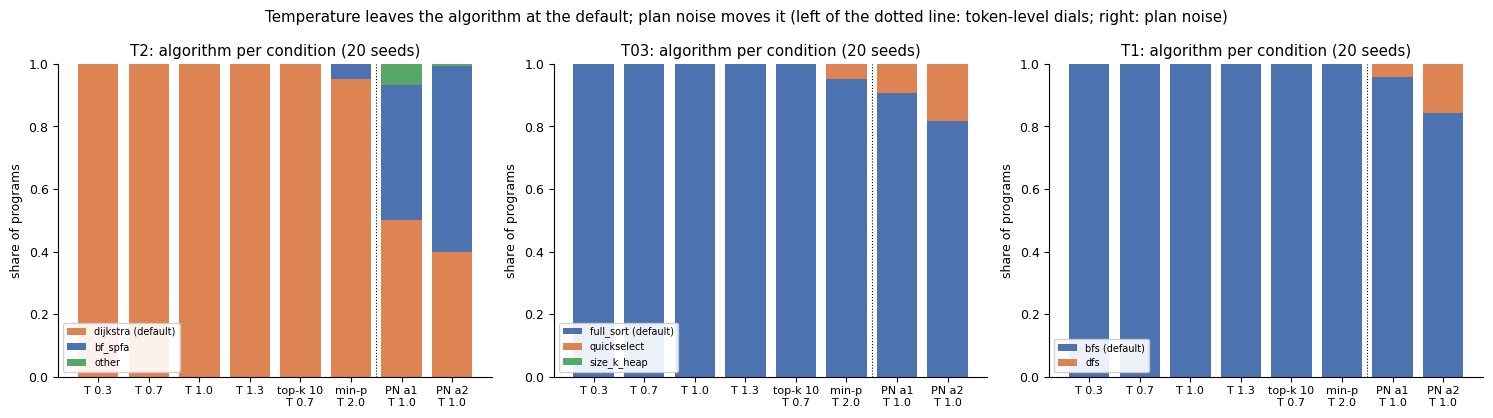

F1_coupling_map


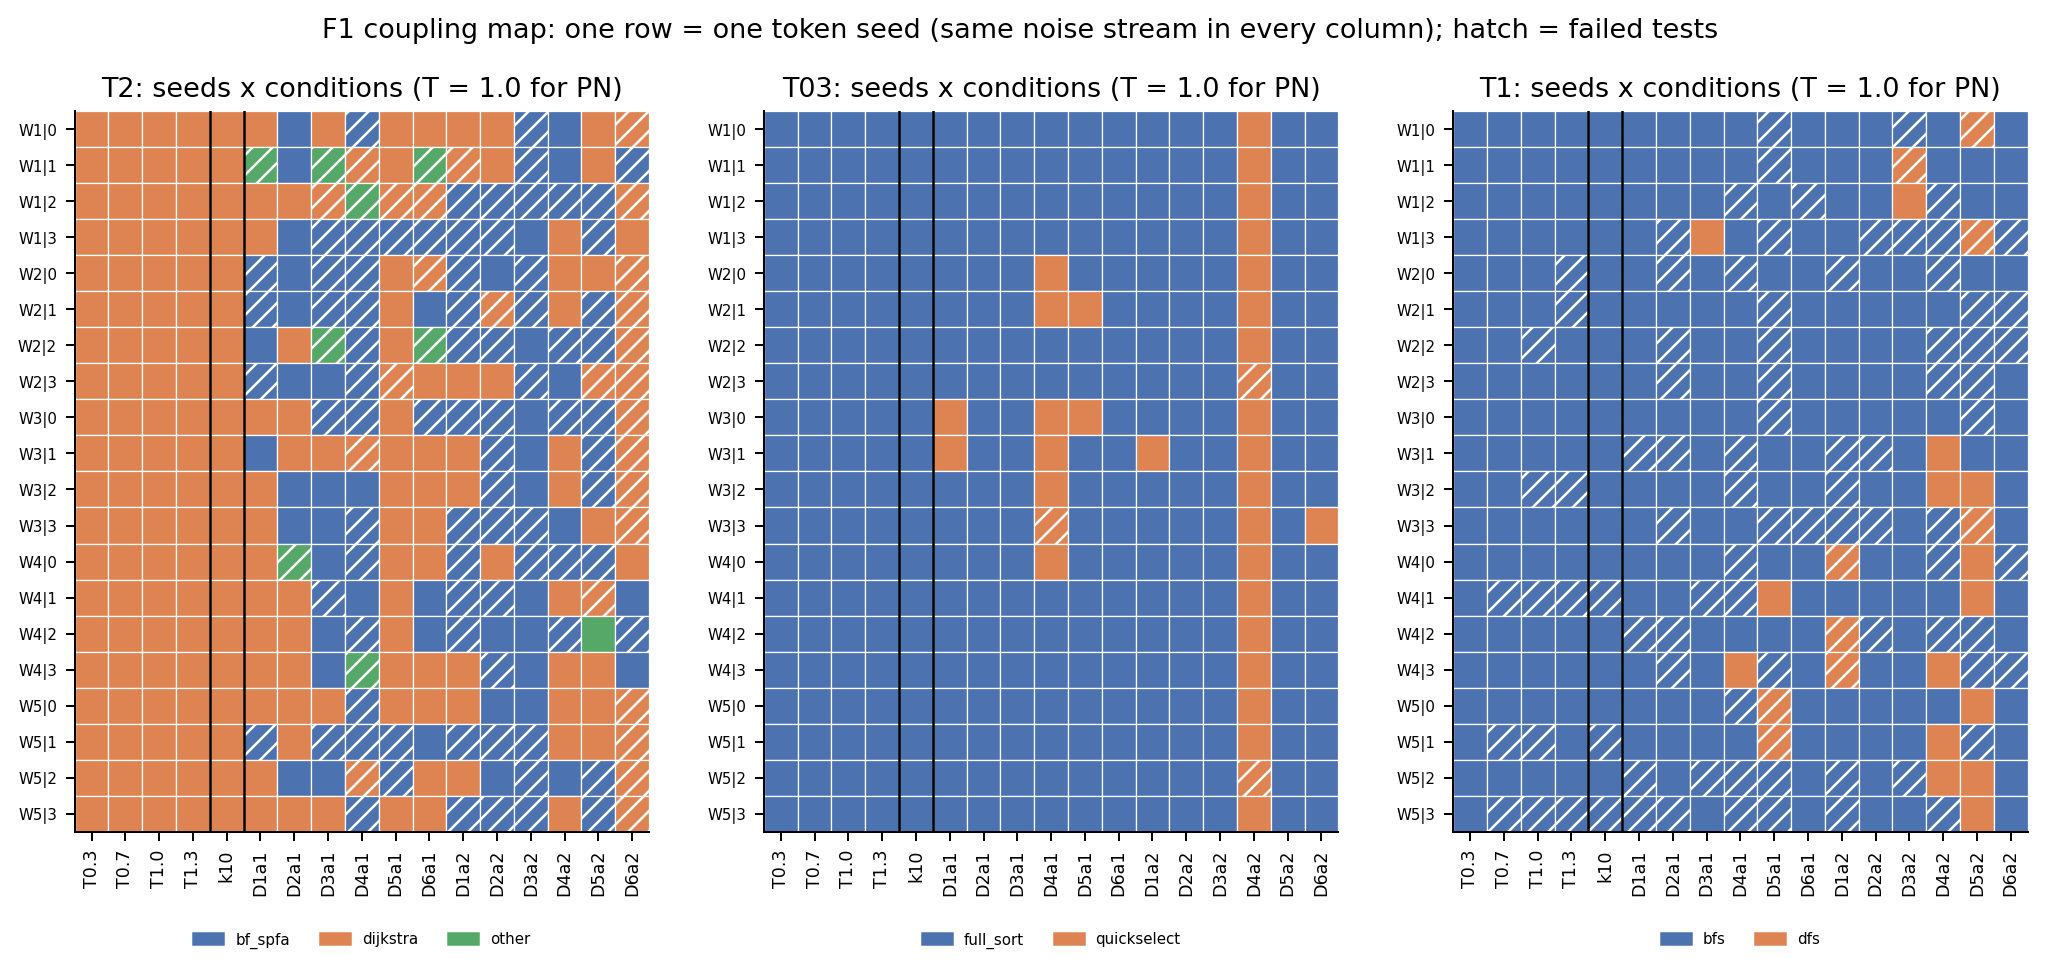

F3_changed_seed_counts


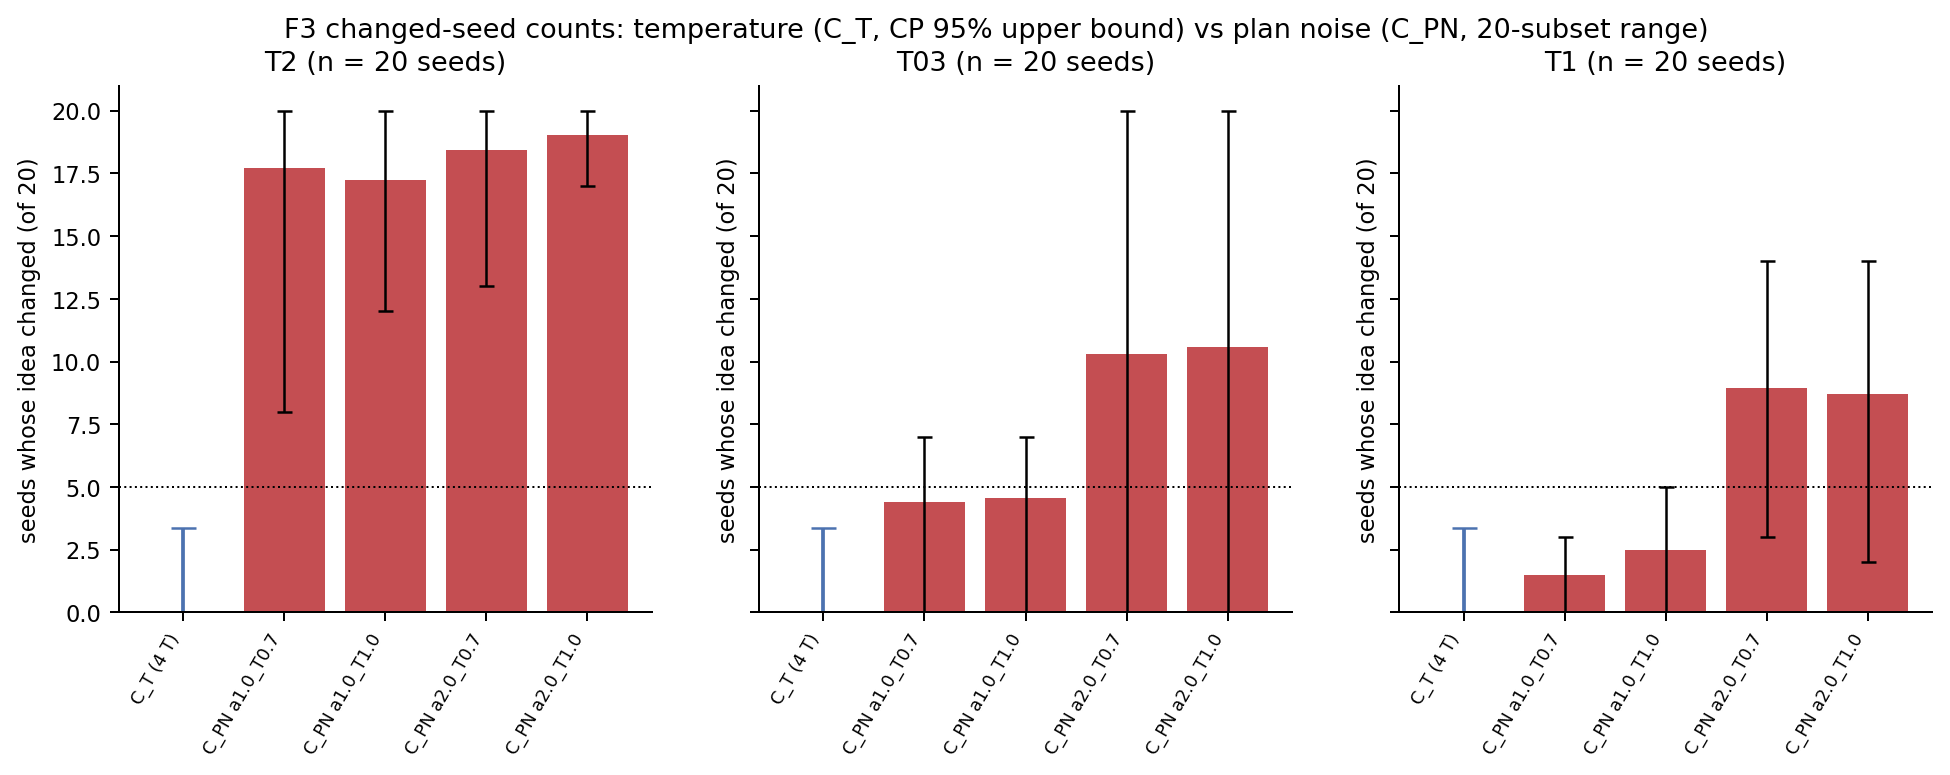

F5_theta_sweep


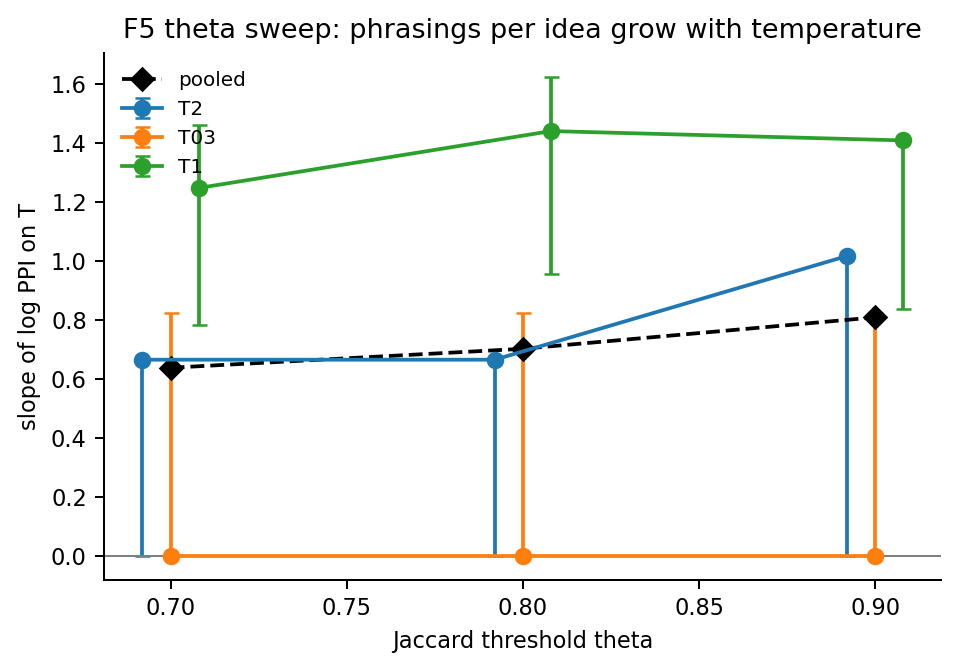

F2_hill_vs_ppi


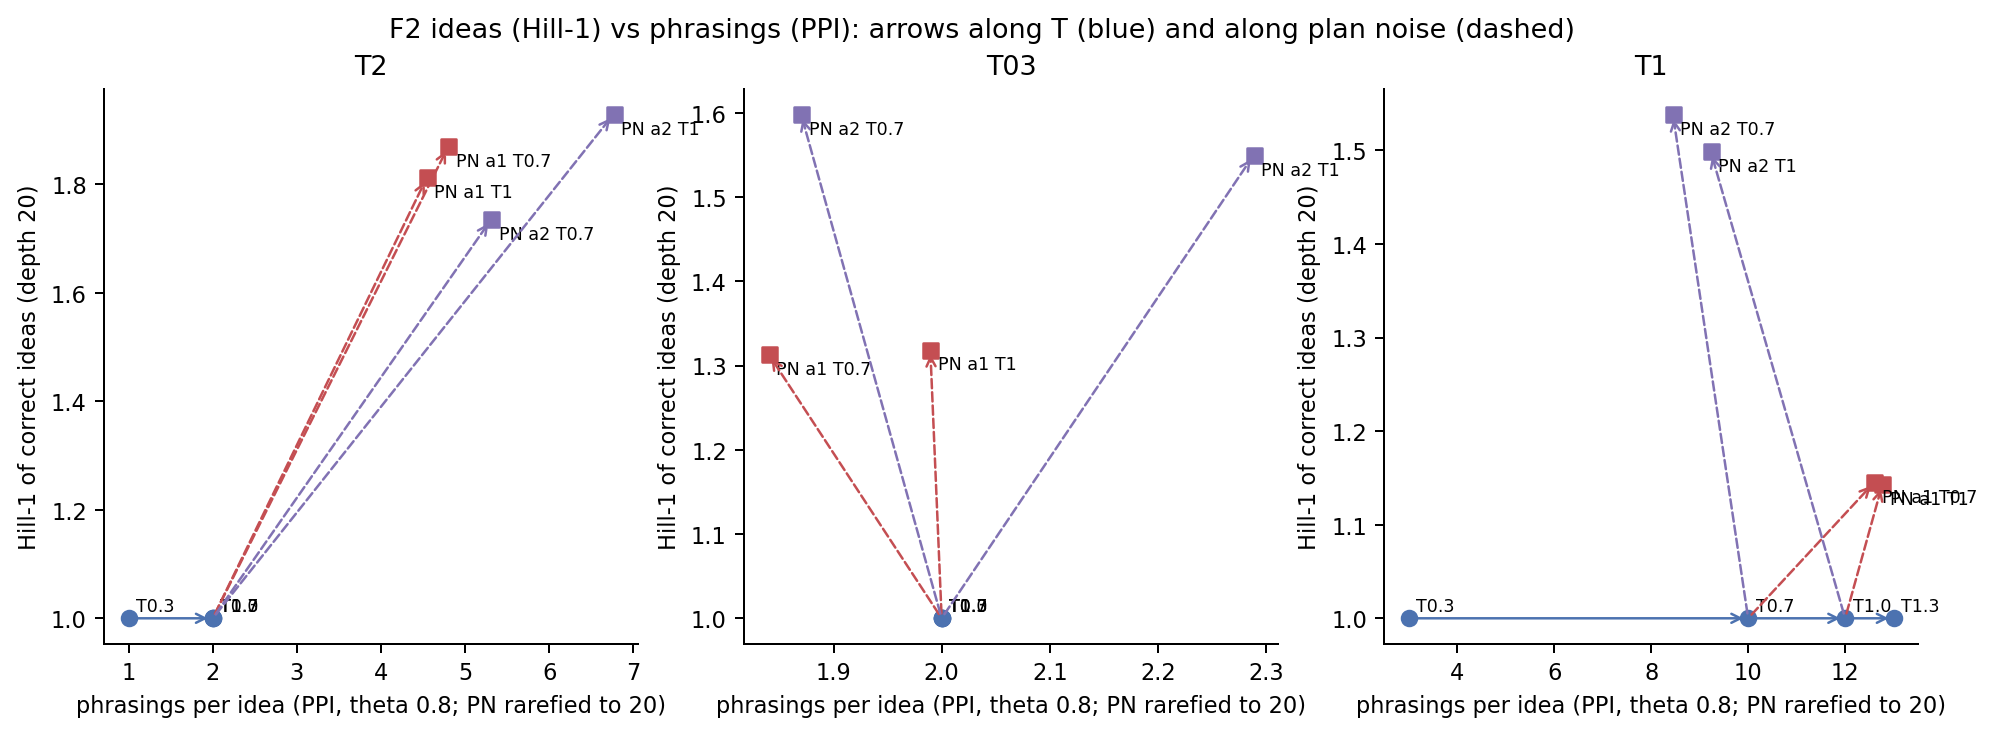

In [29]:
rep = data["metadata"]["reported"]
nb_phr = read_json(RESULTS_DIR / "phrasing.json")
nb_red = read_json(RESULTS_DIR / "rederive.json")


def _fmt(v):
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(_fmt(x) for x in v) + "]"
    if isinstance(v, (float, np.floating)):
        return f"{float(v):.4g}"
    return str(v)


summary = []
for task in ("T2", "T03", "T1"):
    summary.append((f"C_T {task}: seeds whose algorithm changed across T 0.3-1.3 (of 20)",
                    res["A1_C_T_off"][task]["primary"]["C_T"], rep["c1seed"]["A1_C_T_off"][task]["primary"]["C_T"]))
for task in ("T2", "T03", "T1"):
    for key in ("a1.0_T0.7", "a1.0_T1.0", "a2.0_T0.7", "a2.0_T1.0"):
        summary.append((f"C_PN {task} {key}: seeds changed by plan noise (20-subset mean)",
                        res["A2_C_PN"][task][key]["C_PN"], rep["c1seed"]["A2_C_PN"][task][key]["C_PN"]))
P, RP = res["A3_x_contrast"], rep["c1seed"]["A3_x_contrast"]
summary += [("mean x_s, pooled T2 + T03 (40 seeds)", P["pooled"]["mean_x"], RP["pooled"]["mean_x"]),
            ("  seed-bootstrap 95% CI", P["pooled"]["boot95"], RP["pooled"]["boot95"]),
            ("  one-sided sign-flip p (Holm entry C1-seed)", P["pooled"]["sign_flip"]["p"], RP["pooled"]["sign_flip"]["p"]),
            ("  within-seed permutation p", P["within_seed_permutation_test"]["p"], RP["within_seed_permutation_test"]["p"])]
for th in ("0.7", "0.8", "0.9"):
    summary.append((f"pooled slope of log PPI on T (theta {th})", nb_phr["pooled"][th]["slope"],
                    rep["phrasing"]["pooled"][th]["slope"]))
    summary.append(("  95% CI", nb_phr["pooled"][th]["ci95"], rep["phrasing"]["pooled"][th]["ci95"]))
for task in ("T2", "T03"):
    I, RI = res["interaction"][task], rep["c1seed"]["interaction"][task]
    summary.append((f"{task}: seeds changed by T 0.7 vs 1.0 -- without PN / under the escaping PN direction",
                    f"{I['nopn_T0.7_vs_T1.0_changed']} / {_fmt(I['pn_mean_changed'])}",
                    f"{RI['nopn_T0.7_vs_T1.0_changed']} / {_fmt(RI['pn_mean_changed'])}"))
for task in ("T2", "T03", "T1"):
    summary.append((f"filler repeat byte-identical to NOPN_T1.0 ({task})", res["determinism"][task]["filler_repeat_byte_identical"],
                    rep["determinism"][task]["filler_repeat_byte_identical"]))
summary += [("verdict", res["verdict"]["verdict"], rep["c1seed"]["verdict"]["verdict"]),
            ("failed parts", ", ".join(res["verdict"]["failed_parts"]) or "-",
             ", ".join(rep["c1seed"]["verdict"]["failed_parts"]) or "-"),
            ("re-derivation mismatches", f"{nb_red['mismatches']} of {len(nb_red['checks'])} checks",
             f"{rep['rederive']['mismatches']} of {len(rep['rederive']['checks'])} checks"),
            ("hash-chain breaks", nb_red["hash_chain_breaks"], rep["rederive"]["hash_chain_breaks"])]
pd.set_option("display.max_colwidth", 80)
display(pd.DataFrame([(q, _fmt(a), _fmt(b)) for q, a, b in summary],
                     columns=["quantity", "this notebook", "reported (full run)"]))


# the 1a-c question, per condition: how many correct IDEAS (Hill-1) and how many PHRASINGS per idea (PPI, theta 0.8)
def _hill(r):   # as in f2_hill_ppi: PN cells carry the rarefied Hill-1
    h = r.get("hill1_correct", r.get("hill1_correct_rarefied20"))
    return h if h is not None else r.get("hill1_correct_rarefied20")


def _r2(v):
    return None if v is None else round(float(v), 2)


t1ac = pd.DataFrame([{"task": r["task"], "condition": r["condition"], "N programs": r["N"], "pass rate": _r2(r["pass_rate"]),
                      "ideas: Hill-1 of correct": _r2(_hill(r)), "phrasing clusters (theta 0.8)": r["clusters"]["0.8"],
                      "phrasings per idea (theta 0.8)": _r2((r.get("ppi_rarefied20") or r["ppi"])["0.8"]),
                      "algorithms attempted": ", ".join(f"{k} {v}" for k, v in r["attempted"].items())}
                     for r in read_json(RESULTS_DIR / "table_1ac.json") if not r["condition"].startswith("GB_")])
display(t1ac)

# where do the programs land? algorithm composition per condition (all 20 seeds of a task, PN pooled over 6 directions)
rows_all = load_rows()
conds = [("T 0.3", ["NOPN_T0.3"]), ("T 0.7", ["NOPN_T0.7"]), ("T 1.0", ["NOPN_T1.0"]), ("T 1.3", ["NOPN_T1.3"]),
         ("top-k 10\nT 0.7", ["TOPK10_T0.7"]), ("min-p\nT 2.0", ["MINP_T2.0"]),
         ("PN a1\nT 1.0", [cond_pn(d, 1.0, 1.0) for d in PN_SEEDS]), ("PN a2\nT 1.0", [cond_pn(d, 2.0, 1.0) for d in PN_SEEDS])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, task in zip(axes, ("T2", "T03", "T1")):
    colour = {l: PALETTE[i] for i, l in enumerate(sorted({r["label"] for r in rows_all if r["task"] == task}))}  # as in F1
    labs = [DEFAULT4[task]] + sorted(set(colour) - {DEFAULT4[task]})   # default algorithm at the bottom of each bar
    bottom = np.zeros(len(conds))
    for i, l in enumerate(labs):
        share = np.array([np.mean([r["label"] == l for r in rows_all if r["task"] == task and r["arm"] in arms])
                          for _, arms in conds])
        ax.bar(range(len(conds)), share, bottom=bottom, color=colour[l], label=l + (" (default)" if i == 0 else ""))
        bottom += share
    ax.axvline(5.5, color="k", lw=0.8, ls=":")
    ax.set_xticks(range(len(conds)), [c for c, _ in conds], fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_ylabel("share of programs")
    ax.set_title(f"{task}: algorithm per condition (20 seeds)")
    ax.legend(fontsize=7, loc="lower left", framealpha=0.9)
fig.suptitle("Temperature leaves the algorithm at the default; plan noise moves it (left of the dotted line: "
             "token-level dials; right: plan noise)")
fig.tight_layout()
plt.show()

# the analysis figures written by the analyse stage
for name in ("F1_coupling_map", "F3_changed_seed_counts", "F5_theta_sweep", "F2_hill_vs_ppi"):
    print(name)
    display(Image(filename=str(FIG_DIR / f"{name}.png")))

### Reading the results
- **F1, coupling map.** Each row is one token seed, with the same noise stream in every column.
  - The four temperature columns and the top-k column always have the same colour: **0/20 seeds change their
    algorithm** on any task.
  - The plan-noise columns break that, most of all on T2, where they switch to Bellman-Ford/SPFA.
- **The 1a–c question: one idea, more phrasings.** In the second table, the result is the same on every task:
  - *Tight temperature (or top-k 10) gives one idea in a few phrasings.* Every temperature and top-k 10 give
    Hill-1 = 1.00, i.e. a single correct idea.
  - *Loosening T multiplies phrasings of that idea, not ideas.* On T1 the phrasing clusters (θ 0.8) grow from 3 at
    T 0.3 to 10, 12 and 13 at T 0.7, 1.0 and 1.3. On T2 they grow from 1 to 2, and on T03 they stay at 2.
  - Even min-p at T 2.0 moves only 1 seed in 20 (T2, T03).
  - *Plan noise is what adds ideas.* Hill-1 is about 1.8–1.9 on T2 (Dijkstra and Bellman-Ford/SPFA) at a
    correctness cost (pass rate 0.63 at α 1, T 1.0).
- **Temperature is not the creativity knob for ideas.** It acts on the token level after the plan is fixed:
  phrasings per idea grow with T (F5; mostly on T1), while the algorithm stays put. Temperature only starts to
  matter for the idea once the plan has been nudged off the default. Under the escaping direction, T 0.7 vs 1.0
  changes 5/20 seeds on T2 and 2/20 on T03, against 0/20 without PN (the `interaction` row of the first table).
- **The decisive test is paired within seed.** Mean `x_s` = 0.545 over 40 seeds, sign-flip p ≈ 1e-5.
- **The verdict is PARTIAL, as pre-registered.** H-PN fails on T03, where `C_PN` = 4.55 < 5. There, the
  protocol-v4 unit is about 0.77× the screen's unit, so α 1 is a weaker push (README deviation D4). At α 2, T03
  reaches 10.6.

The configuration cell already uses the original Monte-Carlo sizes; the three CPU stages take well under a minute.
Lower them for a quicker, coarser run. Regenerating the programs themselves needs the GPU stages of the original
artifact (`README.md` there): Qwen3-8B FP8 on a 16 GB GPU, about 2.6 GPU-hours.